# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Ryan Fang, Eloise McDonough, Sufyan Billel

**Date:** 11/09/2026

In [1]:
# Your Phase 1 solution to the problem goes here.


# Q1:

Original dataset shape: (16814, 19)

Missing values per column:


sale_price_nan                         0
house_square_feet_nan                  0
attic_finished_square_feet_nan         0
basement_square_feet_nan               0
attached_garage_square_feet_nan        0
detached_garage_square_feet_nan        0
fireplaces_nan                         0
stories_nan                            0
year_built_nan                         0
bedrooms_nan                           0
bathrooms_nan                          0
hvac_description_nan                   7
exterior_nan                           1
interior_nan                           7
roof_cover_nan                         8
waterfront_type_nan                16261
view_quality_nan                   15895
utility_sewer_nan                      0
dtype: int64


3xIQR Log-Price Fences: $102,201 to $1,782,700
Cleaned dataset shape after removing missing and impossible/outlier records: (16509, 55)

Summary statistics of cleaned numeric features:


,sale_price_clean,house_square_feet_clean,attic_finished_square_feet_clean,basement_square_feet_clean,attached_garage_square_feet_clean,detached_garage_square_feet_clean,fireplaces_clean,stories_clean,year_built_clean,bedrooms_clean,bathrooms_clean
count,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00
mean,456202.68,1883.34,24.39,166.79,365.72,37.90,0.89,1.57,1980.63,3.29,2.32
std,182979.12,743.00,100.46,426.47,283.76,163.21,0.59,0.51,33.28,0.85,0.81
min,103200.00,400.00,0.00,0.00,0.00,0.00,0.00,1.00,1880.00,1.00,1.00
25%,350000.00,1330.00,0.00,0.00,0.00,0.00,1.00,1.00,1959.00,3.00,2.00
50%,417500.00,1779.00,0.00,0.00,424.00,0.00,1.00,2.00,1990.00,3.00,2.00
75%,521000.00,2352.00,0.00,0.00,528.00,0.00,1.00,2.00,2006.00,4.00,3.00
max,1775000.00,6963.00,1212.00,4000.00,2816.00,3664.00,5.00,3.00,2021.00,9.00,8.00


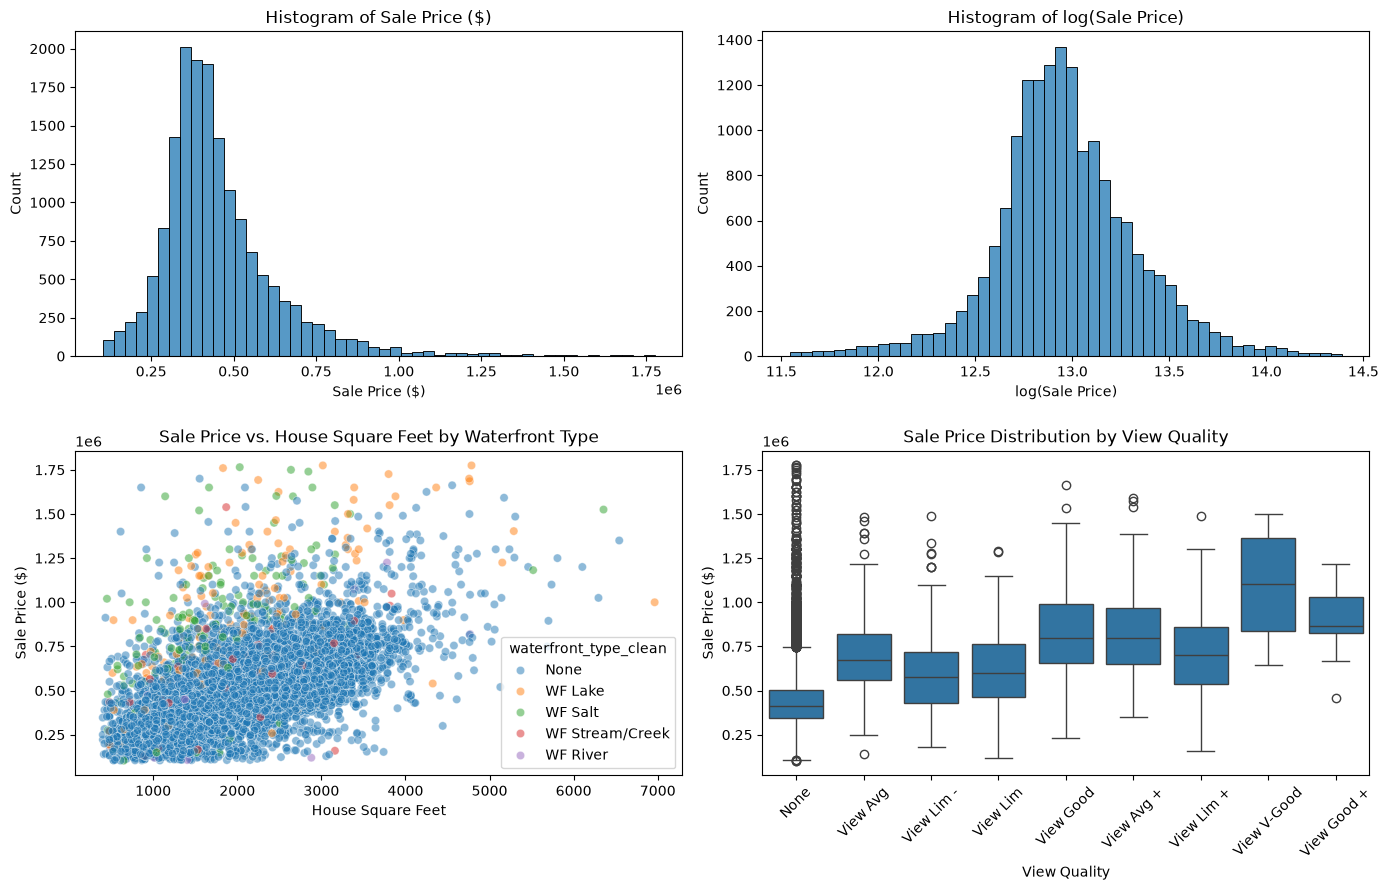

Correlation Matrix of Key Numeric Features:


,sale_price_clean,house_square_feet_clean,bathrooms_clean,bedrooms_clean,attached_garage_square_feet_clean,year_built_clean
sale_price_clean,1.000,0.612,0.489,0.282,0.372,0.284
house_square_feet_clean,0.612,1.000,0.738,0.595,0.563,0.541
bathrooms_clean,0.489,0.738,1.000,0.565,0.527,0.603
bedrooms_clean,0.282,0.595,0.565,1.000,0.304,0.330
attached_garage_square_feet_clean,0.372,0.563,0.527,0.304,1.000,0.637
year_built_clean,0.284,0.541,0.603,0.330,0.637,1.000


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# load the dataset
df = pd.read_csv('data/pierce_county_house_sales.csv')
print("Original dataset shape:", df.shape)

# define numeric and categorical columns
num_cols = [
    'sale_price', 'house_square_feet', 'attic_finished_square_feet',
    'basement_square_feet', 'attached_garage_square_feet',
    'detached_garage_square_feet', 'fireplaces', 'stories',
    'year_built', 'bedrooms', 'bathrooms'
]

cat_cols = [
    'hvac_description', 'exterior', 'interior', 'roof_cover',
    'waterfront_type', 'view_quality', 'utility_sewer'
]

# coerce numeric variables to numeric and track missingness with _nan columns
for col in num_cols:
    df[f'{col}_clean'] = pd.to_numeric(df[col], errors='coerce')
    df[f'{col}_nan'] = df[f'{col}_clean'].isnull()

# clean categorical variables and track missingness with _nan columns
for col in cat_cols:
    df[f'{col}_nan'] = df[col].isnull()
    if col in ['waterfront_type', 'view_quality']:
        # NaN for waterfront_type and view_quality indicates no waterfront or special view
        df[f'{col}_clean'] = df[col].fillna('None')
    else:
        df[f'{col}_clean'] = df[col]

# fix typo in hvac_description ('Floor Wall Furnace' -> 'Floor/Wall Furnace')
df['hvac_description_clean'] = df['hvac_description_clean'].replace({
    'Floor Wall Furnace': 'Floor/Wall Furnace',
    'Electric': 'Electric Baseboard'
})

print("\nMissing values per column:")
display(df[[f'{c}_nan' for c in num_cols + cat_cols]].sum())

# drop the 17 rows with missing values in hvac_description, exterior, interior, or roof_cover
clean_cols = [f'{c}_clean' for c in num_cols + cat_cols]
df_clean = df.dropna(subset=clean_cols).copy()

# filter out impossible data entry errors (e.g., 1 sq ft house, 25 bedrooms, 0 bathrooms/stories)
# and trim extreme non-market/luxury price outliers using 3 x IQR fences on log(sale_price)
log_price = np.log(df_clean['sale_price_clean'])
q25, q75 = np.percentile(log_price, [25, 75])
iqr = q75 - q25
low_fence, high_fence = np.exp(q25 - 3 * iqr), np.exp(q75 + 3 * iqr)
print(f"\n3xIQR Log-Price Fences: ${low_fence:,.0f} to ${high_fence:,.0f}")

valid_houses = (
    (df_clean['sale_price_clean'] > low_fence) &
    (df_clean['sale_price_clean'] < high_fence) &
    (df_clean['house_square_feet_clean'] >= 400) &
    (df_clean['bedrooms_clean'].between(1, 10)) &
    (df_clean['bathrooms_clean'] > 0) &
    (df_clean['stories_clean'] > 0)
)
df_clean = df_clean.loc[valid_houses].copy()
print(f"Cleaned dataset shape after removing missing and impossible/outlier records: {df_clean.shape}")

# summary statistics of cleaned numeric variables
print("\nSummary statistics of cleaned numeric features:")
display(df_clean[[f'{c}_clean' for c in num_cols]].describe().round(2))

# EDA visualizations: Raw vs. Log Sale Price, House Sq Ft, and View Quality Boxplot
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(data=df_clean, x='sale_price_clean', bins=50, ax=axes[0, 0])
axes[0, 0].set_title("Histogram of Sale Price ($)")
axes[0, 0].set_xlabel("Sale Price ($)")

sns.histplot(x=np.log(df_clean['sale_price_clean']), bins=50, ax=axes[0, 1])
axes[0, 1].set_title("Histogram of log(Sale Price)")
axes[0, 1].set_xlabel("log(Sale Price)")

sns.scatterplot(
    data=df_clean,
    x='house_square_feet_clean',
    y='sale_price_clean',
    hue='waterfront_type_clean',
    alpha=0.5,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Sale Price vs. House Square Feet by Waterfront Type")
axes[1, 0].set_xlabel("House Square Feet")
axes[1, 0].set_ylabel("Sale Price ($)")

sns.boxplot(data=df_clean, x='view_quality_clean', y='sale_price_clean', ax=axes[1, 1])
axes[1, 1].set_title("Sale Price Distribution by View Quality")
axes[1, 1].set_xlabel("View Quality")
axes[1, 1].set_ylabel("Sale Price ($)")
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Correlation matrix of primary numeric predictors
print("Correlation Matrix of Key Numeric Features:")
display(df_clean[[
    'sale_price_clean', 'house_square_feet_clean', 'bathrooms_clean',
    'bedrooms_clean', 'attached_garage_square_feet_clean', 'year_built_clean'
]].corr().round(3))

The raw Pierce County dataset has 16,814 rows and 19 columns. None of the numeric columns have missing values. Waterfront type has 16,261 missing entries and view quality has 15,895 missing entries because a blank entry just means the house does not have waterfront access or a rated view. We filled those blanks with None and created indicator columns to track which values were originally missing. We also fixed a spelling mistake in the heating description column and dropped 17 rows that were missing heating, exterior, interior, or roof cover information.

Looking at the summary statistics and distributions showed a few clear data entry mistakes, including a 1 square foot house, a 25 bedroom house, and homes recorded with 0 stories, 0 bedrooms, or 0 bathrooms. There were also extreme price outliers like $2,000 non-market transfers and a $6.13 million estate. We trimmed prices outside 3 times the interquartile range on log sale price, which kept sales between $102,201 and $1,782,700, and required at least 400 square feet, 1 to 10 bedrooms, and at least 1 bathroom and 1 story. That left 16,509 clean house sales.

In our plots and correlation table, sale price is heavily skewed to the right in dollars but looks like a bell curve on a log scale. House square footage has the strongest correlation with sale price at 0.612, followed by bathrooms at 0.489 and attached garage size at 0.372. Waterfront homes on saltwater or lakes and homes with higher view ratings also sell for much more than typical homes.

# Q2:

In [3]:
# separate numeric predictors and categorical predictors
clean_num_features = [f'{c}_clean' for c in num_cols if c != 'sale_price']
clean_cat_features = [f'{c}_clean' for c in cat_cols]

# one-hot encode categorical variables using pd.get_dummies
X_dummies = pd.get_dummies(df_clean[clean_cat_features], drop_first=True, dtype=int)

# combine numeric features and one-hot encoded dummy variables into feature matrix X
X = pd.concat([df_clean[clean_num_features], X_dummies], axis=1)
y = df_clean['sale_price_clean']

print(f"Feature matrix X shape: {X.shape}")
print("First 5 rows of transformed feature matrix:")
display(X.head())

Feature matrix X shape: (16509, 49)
First 5 rows of transformed feature matrix:


,house_square_feet_clean,attic_finished_square_feet_clean,basement_square_feet_clean,attached_garage_square_feet_clean,detached_garage_square_feet_clean,fireplaces_clean,stories_clean,year_built_clean,bedrooms_clean,bathrooms_clean,...,view_quality_clean_View Good,view_quality_clean_View Good +,view_quality_clean_View Lim,view_quality_clean_View Lim +,view_quality_clean_View Lim -,view_quality_clean_View V-Good,utility_sewer_clean_SEWER/SEPTIC AVAIL,utility_sewer_clean_SEWER/SEPTIC INSTALLED,utility_sewer_clean_SEWER/SEPTIC NO,utility_sewer_clean_SEWER/SEPTIC NO PERC
0,2157,0,0,528,0,0,2,1993,3,3,...,0,0,0,0,0,0,0,1,0,0
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,1,0,0
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,1,0,0
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,1,0,0
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,1,0,0


Regression models require numeric inputs, so we converted all seven categorical columns into binary 0 and 1 indicator variables using one-hot encoding. We dropped the first category of each variable to act as the baseline reference group so the indicators do not overlap with the intercept. Combining the 10 cleaned numeric variables with the 39 indicator columns gives a feature table with 49 predictors across our 16,509 houses.

# Q3:

In [4]:
from sklearn.model_selection import train_test_split

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=100)

print(f"Training set shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Test set shape:     X_test  = {X_test.shape},  y_test  = {y_test.shape}")

Training set shape: X_train = (13207, 49), y_train = (13207,)
Test set shape:     X_test  = (3302, 49),  y_test  = (3302,)


We split the cleaned data 80/20 into 13,207 training observations and 3,302 test observations using a fixed random seed of 100 so our results stay reproducible. We set the test data aside to measure how well our models predict unseen houses.

# Q4:

In [5]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, r2_score

# define simple linear models with no transformations or interactions
model0_cols = ['house_square_feet_clean']
model1_cols = ['house_square_feet_clean', 'bedrooms_clean', 'bathrooms_clean', 'stories_clean']
model2_cols = clean_num_features
model3_cols = list(X.columns)

models = [
    ('Model 1: House Square Feet Only', model0_cols),
    ('Model 2: Core Size & Rooms Only', model1_cols),
    ('Model 3: All Numeric Features', model2_cols),
    ('Model 4: All Numeric + Categorical Dummies', model3_cols)
]

results = []
for name, cols in models:
    reg = LinearRegression().fit(X_train[cols], y_train)
    
    y_train_pred = reg.predict(X_train[cols])
    y_test_pred = reg.predict(X_test[cols])
    
    results.append({
        'Model': name,
        'Train RMSE': root_mean_squared_error(y_train, y_train_pred),
        'Test RMSE': root_mean_squared_error(y_test, y_test_pred),
        'Train R^2': r2_score(y_train, y_train_pred),
        'Test R^2': r2_score(y_test, y_test_pred)
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 1: House Square Feet Only,143433.7923,149452.1518,0.3801,0.3547
1,Model 2: Core Size & Rooms Only,138053.1573,143852.9723,0.4257,0.4022
2,Model 3: All Numeric Features,124472.7312,129726.0976,0.5332,0.5138
3,Model 4: All Numeric + Categorical Dummies,111190.6127,113873.3810,0.6275,0.6254


We built and compared four linear models without any transformations or interaction terms:
1. **Model 1:** Uses only house square footage. It performs the worst, with a training RMSE of $143,433.79 and training $R^2$ of 0.3801, and a test RMSE of $149,452.15 and test $R^2$ of 0.3547.
2. **Model 2:** Uses house square footage, bedrooms, bathrooms, and stories. It improves to a training RMSE of $138,053.16 and training $R^2$ of 0.4257, and a test RMSE of $143,852.97 and test $R^2$ of 0.4022.
3. **Model 3:** Uses all 10 numeric predictors by adding attic, basement, and garage square footage along with fireplaces and year built. Prediction error drops to a training RMSE of $124,472.73 and training $R^2$ of 0.5332, and a test RMSE of $129,726.10 and test $R^2$ of 0.5138.
4. **Model 4:** Includes all 10 numeric predictors plus all 39 categorical indicator columns. Model 4 does the best by a wide margin, reaching the lowest training RMSE of $111,190.61 and highest training $R^2$ of 0.6275, as well as the lowest test RMSE of $113,873.38 and highest test $R^2$ of 0.6254. Training and test scores are very close across all four models, which shows they are not overfitting, and adding categorical features like waterfront access, view quality, and heating type captures important price differences that house size alone misses.

# Q5:

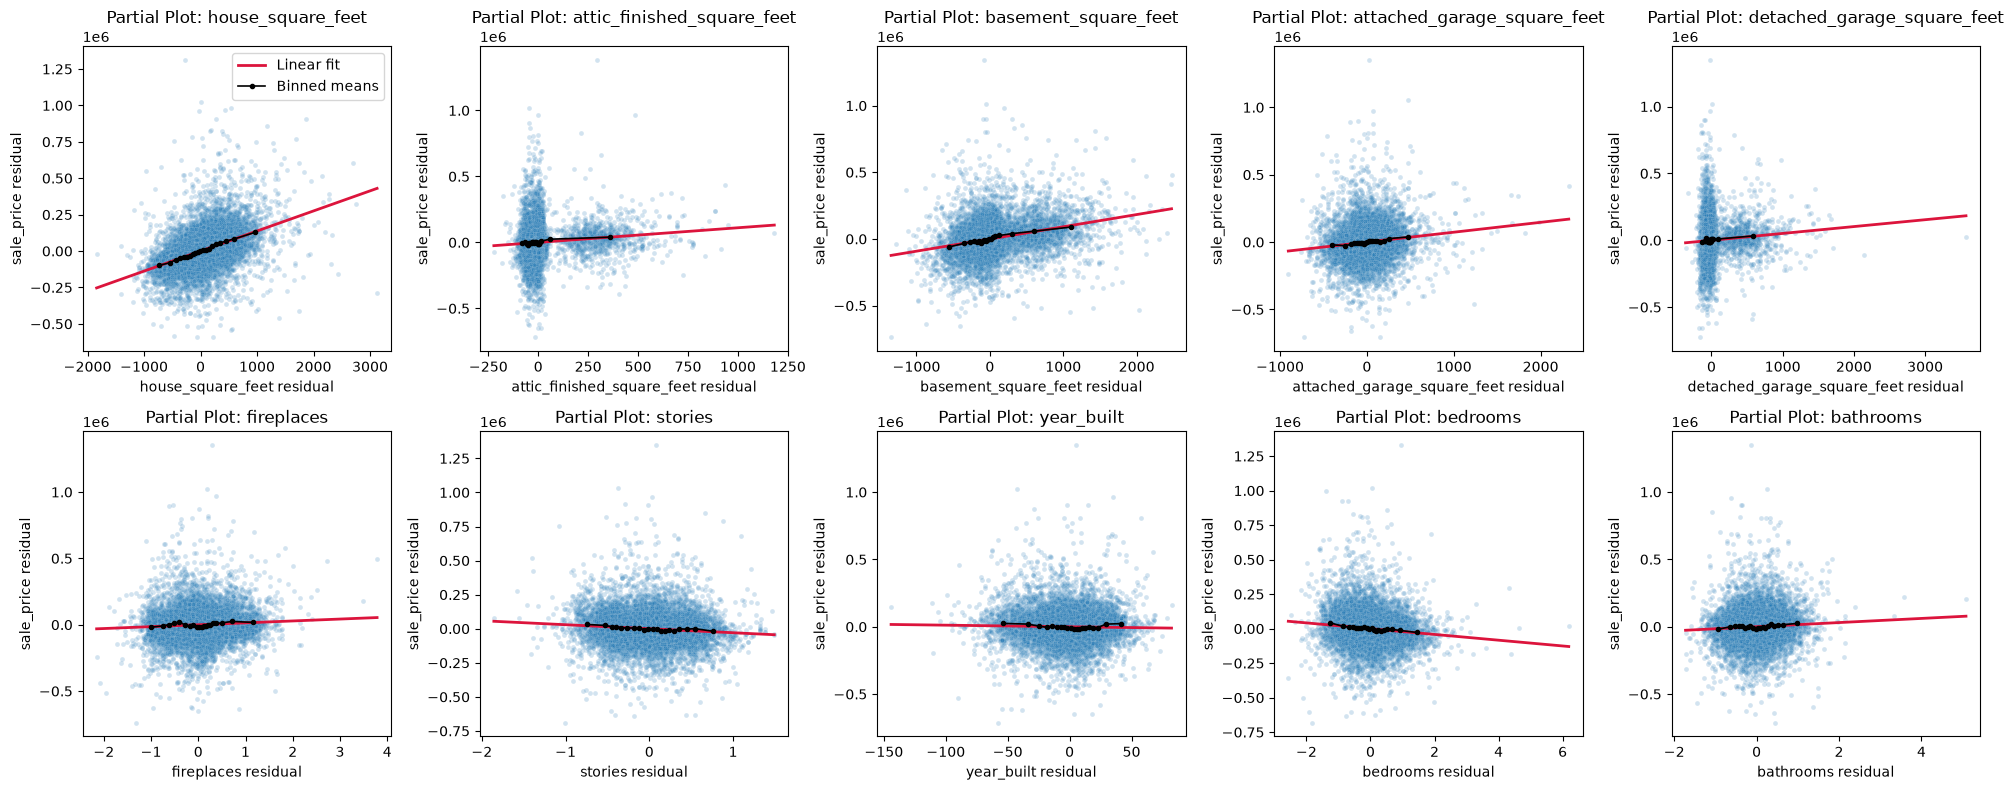

In [6]:
# make partial correlation (partial regression) plots for each numeric variable in Model 4
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

all_model4_cols = list(X_train.columns)

for i, var in enumerate(clean_num_features):
    # regress y_train and x_k on all other features in Model 4 (numeric + categorical dummies)
    other_vars = [c for c in all_model4_cols if c != var]
    
    reg_y = LinearRegression().fit(X_train[other_vars], y_train)
    res_y = y_train - reg_y.predict(X_train[other_vars])
    
    reg_x = LinearRegression().fit(X_train[other_vars], X_train[var])
    res_x = X_train[var] - reg_x.predict(X_train[other_vars])
    
    # fit simple linear regression on the residuals for the partial trend line
    reg_part = LinearRegression().fit(res_x.values.reshape(-1, 1), res_y)
    
    sns.scatterplot(x=res_x, y=res_y, alpha=0.2, ax=axes[i], s=12)
    x_vals = np.linspace(res_x.min(), res_x.max(), 100)
    axes[i].plot(x_vals, reg_part.predict(x_vals.reshape(-1, 1)), color='crimson', linewidth=2, label='Linear fit')
    
    # overlay 20-quantile binned means to reveal non-linear curvature
    bins = pd.qcut(res_x, q=20, duplicates='drop')
    binned = pd.DataFrame({'res_x': res_x, 'res_y': res_y}).groupby(bins, observed=True).mean()
    axes[i].plot(binned['res_x'], binned['res_y'], color='black', marker='o', markersize=3, linewidth=1.2, label='Binned means')
    
    clean_label = var.replace('_clean', '')
    axes[i].set_title(f"Partial Plot: {clean_label}")
    axes[i].set_xlabel(f"{clean_label} residual")
    axes[i].set_ylabel("sale_price residual")

axes[0].legend()
plt.tight_layout()
plt.show()

Each plot shows the residuals of sale price against the residuals of one numeric predictor after accounting for every other feature in Model 4. The red line shows the straight linear fit and the black dots show the average across 20 equal-sized bins to make curved patterns easier to spot:
* **House, basement, and garage square footage:** The binned averages curve upward at the right tail and the vertical spread of price errors fans out for very large homes. Because most houses have zero attic, basement, or detached garage space, a large share of points pile up along a straight boundary line where the raw feature equals zero. This suggests that transforming skewed area variables can help capture diminishing returns and separate homes that have these spaces from homes that do not.
* **Year built:** The binned averages show a clear U-shaped pattern. Older historic homes on the left and brand-new homes on the right both sit above the straight trend line compared to mid-century homes built from the 1960s to the 1980s.
* **Bedrooms, bathrooms, stories, and fireplaces:** Once square footage is held constant, bedrooms has a negative slope because dividing the same floor area into more bedrooms makes the individual rooms smaller, whereas bathrooms and fireplaces still have positive slopes.

# Q6:

In [7]:
from sklearn.preprocessing import PolynomialFeatures


# 1. Build our domain-informed complex model (Model 5) with transformations and interactions
def create_complex_features(df_in):
  X_comp = df_in.copy()

  # convert year_built to age (all sales are in 2020) and drop year_built_clean to avoid perfect collinearity
  X_comp['age'] = 2020 - X_comp['year_built_clean']
  X_comp['age_sq'] = X_comp['age'] ** 2
  X_comp = X_comp.drop(columns=['year_built_clean'])

  # apply inverse hyperbolic sine (arcsinh) transformation to skewed/zero-heavy area variables
  area_vars = [
      'house_square_feet_clean',
      'attic_finished_square_feet_clean',
      'basement_square_feet_clean',
      'attached_garage_square_feet_clean',
      'detached_garage_square_feet_clean',
  ]
  for var in area_vars:
    X_comp[f'{var}_ihs'] = np.arcsinh(X_comp[var])

  # include quadratic terms to capture curvature in size and bathrooms
  X_comp['house_sq_ft_sq'] = X_comp['house_square_feet_clean'] ** 2
  X_comp['basement_sq_ft_sq'] = X_comp['basement_square_feet_clean'] ** 2
  X_comp['bathrooms_sq'] = X_comp['bathrooms_clean'] ** 2

  # include interactions between house size, age, and room/story counts
  X_comp['sqft_x_age'] = X_comp['house_square_feet_clean'] * X_comp['age']
  X_comp['sqft_x_bathrooms'] = (
      X_comp['house_square_feet_clean'] * X_comp['bathrooms_clean']
  )
  X_comp['sqft_x_bedrooms'] = (
      X_comp['house_square_feet_clean'] * X_comp['bedrooms_clean']
  )
  X_comp['sqft_x_stories'] = (
      X_comp['house_square_feet_clean'] * X_comp['stories_clean']
  )
  X_comp['sqft_x_fireplaces'] = (
      X_comp['house_square_feet_clean'] * X_comp['fireplaces_clean']
  )
  X_comp['beds_x_baths'] = X_comp['bedrooms_clean'] * X_comp['bathrooms_clean']

  # interact house_square_feet with waterfront and view quality indicators
  wf_view_cols = [
      c
      for c in df_in.columns
      if c.startswith('waterfront_type_clean_')
      or c.startswith('view_quality_clean_')
  ]
  for col in wf_view_cols:
    X_comp[f'sqft_x_{col}'] = X_comp['house_square_feet_clean'] * X_comp[col]

  return X_comp


X_train_comp = create_complex_features(X_train)
X_test_comp = create_complex_features(X_test)

# inspect correlations of key transformed and interaction terms with y_train (sale_price)
new_terms = [
    'house_square_feet_clean_ihs',
    'house_sq_ft_sq',
    'age',
    'age_sq',
    'sqft_x_bathrooms',
    'sqft_x_bedrooms',
    'sqft_x_fireplaces',
    'beds_x_baths',
    'sqft_x_waterfront_type_clean_WF Salt',
    'sqft_x_waterfront_type_clean_WF Lake',
    'sqft_x_view_quality_clean_View V-Good',
]
print(
    'Correlations of key transformed & interaction features with Training Sale'
    ' Price:'
)
display(
    X_train_comp[new_terms]
    .apply(lambda s: s.corr(y_train))
    .sort_values(ascending=False)
    .round(4)
)

# fit Model 5 (Domain-Informed Complex Model)
reg_comp = LinearRegression().fit(X_train_comp, y_train)
y_train_comp_pred = reg_comp.predict(X_train_comp)
y_test_comp_pred = reg_comp.predict(X_test_comp)

rmse_comp_train = root_mean_squared_error(y_train, y_train_comp_pred)
rmse_comp_test = root_mean_squared_error(y_test, y_test_comp_pred)
r2_comp_train = r2_score(y_train, y_train_comp_pred)
r2_comp_test = r2_score(y_test, y_test_comp_pred)

print(f'\nModel 5 (Domain Complex) Total Features: {X_train_comp.shape[1]}')
print(
    f'Model 5 Training RMSE: ${rmse_comp_train:,.2f} | Training R^2:'
    f' {r2_comp_train:.4f}'
)
print(
    f'Model 5 Test RMSE:     ${rmse_comp_test:,.2f} | Test R^2:    '
    f' {r2_comp_test:.4f}\n'
)

# 2. What happens if we include every possible square and pairwise interaction? (Model 6: Over-complex Degree-2 Expansion)
poly = PolynomialFeatures(degree=2, include_bias=False)
P_train = pd.DataFrame(
    poly.fit_transform(X_train),
    columns=poly.get_feature_names_out(X_train.columns),
    index=X_train.index,
)
P_test = pd.DataFrame(
    poly.transform(X_test), columns=P_train.columns, index=X_test.index
)

# drop duplicate dummy-squared columns and constant zero-product dummy interactions
keep_cols = (~P_train.T.duplicated()) & (P_train.std() > 0)
P_train = P_train.loc[:, keep_cols]
P_test = P_test.loc[:, keep_cols]

reg_poly = LinearRegression().fit(P_train, y_train)
y_train_poly_pred = reg_poly.predict(P_train)
y_test_poly_pred = reg_poly.predict(P_test)

rmse_poly_train = root_mean_squared_error(y_train, y_train_poly_pred)
rmse_poly_test = root_mean_squared_error(y_test, y_test_poly_pred)
r2_poly_train = r2_score(y_train, y_train_poly_pred)
r2_poly_test = r2_score(y_test, y_test_poly_pred)

print(f'Model 6 (Full Degree-2 Expansion) Total Features: {P_train.shape[1]}')
print(
    f'Model 6 Training RMSE: ${rmse_poly_train:,.2f} | Training R^2:'
    f' {r2_poly_train:.4f}'
)
print(
    f'Model 6 Test RMSE:     ${rmse_poly_test:,.2f} | Test R^2:    '
    f' {r2_poly_test:.4f}'
)

Correlations of key transformed & interaction features with Training Sale Price:


house_sq_ft_sq                           0.6164
sqft_x_bathrooms                         0.6087
house_square_feet_clean_ihs              0.5773
sqft_x_fireplaces                        0.5737
sqft_x_bedrooms                          0.5323
beds_x_baths                             0.4527
sqft_x_waterfront_type_clean_WF Lake     0.2385
sqft_x_waterfront_type_clean_WF Salt     0.2345
sqft_x_view_quality_clean_View V-Good    0.1009
age_sq                                  -0.2463
age                                     -0.2884
dtype: float64


Model 5 (Domain Complex) Total Features: 76
Model 5 Training RMSE: $113,516.82 | Training R^2: 0.6117
Model 5 Test RMSE:     $113,486.67 | Test R^2:     0.6279

Model 6 (Full Degree-2 Expansion) Total Features: 730
Model 6 Training RMSE: $104,797.70 | Training R^2: 0.6691
Model 6 Test RMSE:     $112,212.19 | Test R^2:     0.6362


We built two complex models to see how targeted feature engineering compares to our simple models in Q4 and to a full all-pairs polynomial expansion:
1. **Model 5:** This model has 76 features. We replaced year built with house age and age squared, applied the inverse hyperbolic sine transform to the five skewed square footage variables, added squared terms for house size, basement size, and bathrooms, and added interactions between house square footage and age, bathrooms, bedrooms, stories, fireplaces, waterfront access, and view quality. Checking the correlations with training sale price shows strong positive relationships for squared square footage at 0.6164, square footage times bathrooms at 0.6087, transformed square footage at 0.5773, square footage times fireplaces at 0.5737, square footage times bedrooms at 0.5323, bedrooms times bathrooms at 0.4527, and the lake and saltwater waterfront interactions at 0.2385 and 0.2345, while age at -0.2884 and age squared at -0.2463 are negatively correlated with price. These features reflect the idea that extra living space is worth more in a home with waterfront access, a great view, or more bathrooms, and that home age has a curved relationship with price. Model 5 gets a training RMSE of $113,516.82 and training $R^2$ of 0.6117, and it improves on Model 4 on the test set with a lower test RMSE of $113,486.67 and higher test $R^2$ of 0.6279.
2. **Model 6:** This model expands the features into all 730 non-duplicate squares and pairwise interactions. Adding 730 features pushes training RMSE down to $104,797.70 and training $R^2$ up to 0.6691, while test RMSE is $112,212.19 and test $R^2$ is 0.6362. The gap between training and test RMSE widens to $7,414.49 because the extra interaction terms start memorizing noise and rare category combinations in the training data.

# Q7:

,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 1: House Square Feet Only,143433.7923,149452.1518,0.3801,0.3547
1,Model 2: Core Size & Rooms Only,138053.1573,143852.9723,0.4257,0.4022
2,Model 3: All Numeric Features,124472.7312,129726.0976,0.5332,0.5138
3,Model 4: All Numeric + Categorical Dummies,111190.6127,113873.3810,0.6275,0.6254
4,Model 5: Complex Domain Model (Transforms + In...,113516.8212,113486.6671,0.6117,0.6279
5,Model 6: Full Degree-2 Polynomial Expansion,104797.7005,112212.1893,0.6691,0.6362


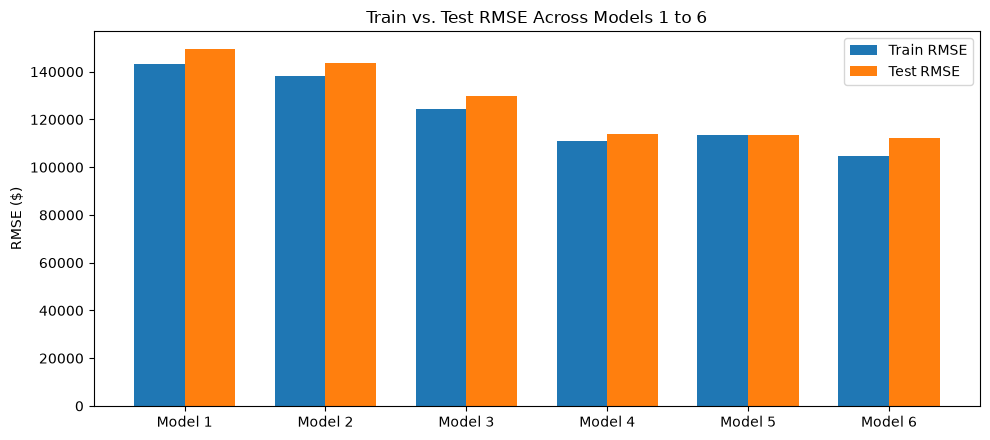

In [8]:
# compile all models from Q4 and Q6 into a single summary table
all_results = results + [
    {
        'Model': 'Model 5: Complex Domain Model (Transforms + Interactions)',
        'Train RMSE': rmse_comp_train,
        'Test RMSE': rmse_comp_test,
        'Train R^2': r2_comp_train,
        'Test R^2': r2_comp_test,
    },
    {
        'Model': 'Model 6: Full Degree-2 Polynomial Expansion',
        'Train RMSE': rmse_poly_train,
        'Test RMSE': rmse_poly_test,
        'Train R^2': r2_poly_train,
        'Test R^2': r2_poly_test,
    },
]

all_results_df = pd.DataFrame(all_results)
display(all_results_df.round(4))

# plot Train vs. Test RMSE across all 6 models
plot_df = all_results_df.copy()
x = np.arange(len(plot_df))

plt.figure(figsize=(10, 4.5))
plt.bar(x - 0.18, plot_df['Train RMSE'], width=0.36, label='Train RMSE')
plt.bar(x + 0.18, plot_df['Test RMSE'], width=0.36, label='Test RMSE')
plt.xticks(x, [m.split(':')[0] for m in plot_df['Model']])
plt.ylabel('RMSE ($)')
plt.title('Train vs. Test RMSE Across Models 1 to 6')
plt.legend()
plt.tight_layout()
plt.show()

Looking across steps 1 through 6, our results highlight a few key lessons about data cleaning, underfitting, overfitting, and model selection:
* **Data cleaning:** Removing impossible data entry mistakes and extreme non-market sale prices kept bad records from pulling the regression slopes off course, and filling missing waterfront and view entries as None kept 98.2 percent of the original sales in our dataset.
* **Underfitting:** Models 1, 2, and 3 were too simple to capture how the market prices homes. Leaving out categorical amenities and nonlinear patterns kept test RMSE high between $129,726.10 and $149,452.15 and test $R^2$ low between 0.3547 and 0.5138. Adding the categorical indicators in Model 4 brought test RMSE down to $113,873.38 and raised test $R^2$ to 0.6254.
* **Overfitting and model selection:** Guided by the partial plots in Q5, adding targeted transformations and interactions in Model 5 improved test RMSE to $113,486.67 and test $R^2$ to 0.6279 with almost no gap between training and test error. Expanding to 730 terms in Model 6 pushed training $R^2$ up to 0.6691 while test $R^2$ trailed at 0.6362, showing how hundreds of unregularized interaction terms begin to overfit the training sample. Because training error always drops when more features are added, we have to rely on held-out test data to choose the best model. Even our most flexible models top out around a test $R^2$ of 0.63 to 0.64 because the dataset does not include location details like neighborhood, school district, or lot size.

# Q8:

Optimal alpha selected via 5-fold CV: 161.03


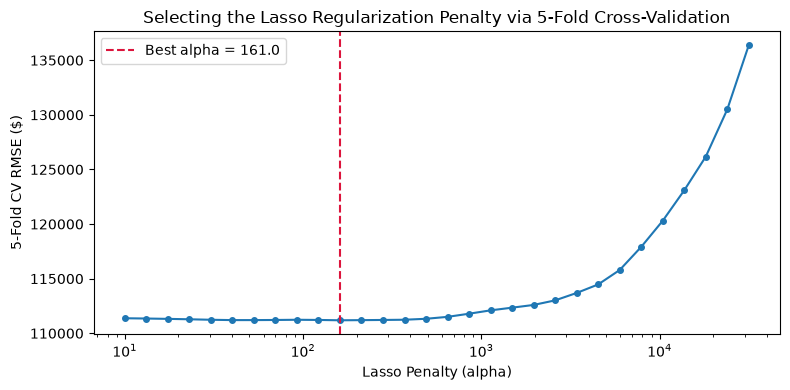

Lasso Training RMSE: $108,575.90 | Training R^2: 0.6448
Lasso Test RMSE:     $111,379.27 | Test R^2:     0.6416

Performance Comparison (Simple vs. Complex OLS vs. Lasso):


,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 4: All Numeric + Categorical Dummies,111190.6127,113873.3810,0.6275,0.6254
1,Model 5: Complex Domain Model (Unregularized OLS),113516.8212,113486.6671,0.6117,0.6279
2,Model 7: Lasso Regularized Complex Model (alph...,108575.8978,111379.2657,0.6448,0.6416



Features selected by Lasso: 62 / 76
Features shrunk to zero:    14 / 76

Top 15 most predictive features selected by Lasso:


,feature,coefficient,abs_coefficient
0,house_square_feet_clean,134335.452054,134335.452054
2,basement_square_feet_clean,49098.820265,49098.820265
3,attached_garage_square_feet_clean,42892.649777,42892.649777
48,age,-38149.481904,38149.481904
61,sqft_x_stories,-32865.253962,32865.253962
49,age_sq,32421.409645,32421.409645
60,sqft_x_bedrooms,-30726.162557,30726.162557
62,sqft_x_fireplaces,27946.993644,27946.993644
53,attached_garage_square_feet_clean_ihs,-27536.638628,27536.638628
43,view_quality_clean_View V-Good,26370.128665,26370.128665



Features eliminated (shrunk to 0) by Lasso:
['stories_clean', 'bedrooms_clean', 'exterior_clean_Frame Hardboard', 'exterior_clean_Frame Siding', 'roof_cover_clean_Composition Shingle', 'roof_cover_clean_Preformed Metal', 'waterfront_type_clean_WF Stream/Creek', 'attic_finished_square_feet_clean_ihs', 'basement_square_feet_clean_ihs', 'house_sq_ft_sq', 'sqft_x_age', 'sqft_x_bathrooms', 'beds_x_baths', 'sqft_x_view_quality_clean_View Avg +']


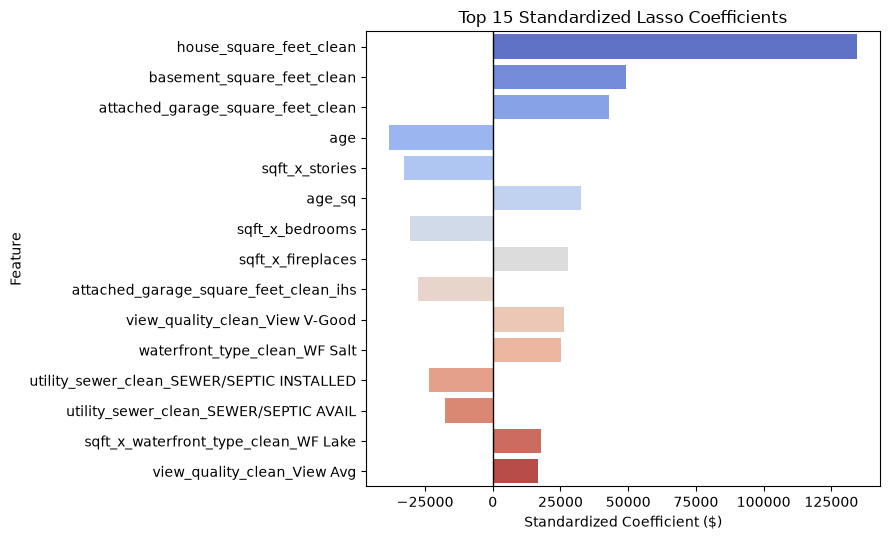

In [9]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LassoCV
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# standardize features using training set mean and std so Lasso penalizes all variables fairly
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_comp),
    columns=X_train_comp.columns,
    index=X_train_comp.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_comp),
    columns=X_test_comp.columns,
    index=X_test_comp.index
)

# tune the Lasso penalty alpha using 5-fold cross-validation on the training set
alphas = np.logspace(1, 4.5, 30)
lasso_cv = LassoCV(alphas=alphas, cv=5, max_iter=10000, random_state=100, n_jobs=-1)
lasso_cv.fit(X_train_scaled, y_train)
best_alpha = lasso_cv.alpha_
print(f"Optimal alpha selected via 5-fold CV: {best_alpha:,.2f}")

# plot the 5-fold CV RMSE path across alpha
plt.figure(figsize=(8, 4))
cv_rmse = np.sqrt(lasso_cv.mse_path_.mean(axis=1))
plt.plot(lasso_cv.alphas_, cv_rmse, marker='o', markersize=4)
plt.axvline(best_alpha, color='crimson', linestyle='--', label=f'Best alpha = {best_alpha:,.1f}')
plt.xscale('log')
plt.xlabel('Lasso Penalty (alpha)')
plt.ylabel('5-Fold CV RMSE ($)')
plt.title('Selecting the Lasso Regularization Penalty via 5-Fold Cross-Validation')
plt.legend()
plt.tight_layout()
plt.show()

# fit Lasso regression model using the CV-selected alpha
lasso = Lasso(alpha=best_alpha, max_iter=10000, random_state=100)
lasso.fit(X_train_scaled, y_train)

y_train_lasso_pred = lasso.predict(X_train_scaled)
y_test_lasso_pred = lasso.predict(X_test_scaled)

rmse_lasso_train = root_mean_squared_error(y_train, y_train_lasso_pred)
rmse_lasso_test = root_mean_squared_error(y_test, y_test_lasso_pred)
r2_lasso_train = r2_score(y_train, y_train_lasso_pred)
r2_lasso_test = r2_score(y_test, y_test_lasso_pred)

print(f"Lasso Training RMSE: ${rmse_lasso_train:,.2f} | Training R^2: {r2_lasso_train:.4f}")
print(f"Lasso Test RMSE:     ${rmse_lasso_test:,.2f} | Test R^2:     {r2_lasso_test:.4f}")

# compare Best Simple (Model 4), Complex OLS (Model 5), and Complex Lasso
lasso_comparison_df = pd.DataFrame([
    results[-1],
    {
        'Model': 'Model 5: Complex Domain Model (Unregularized OLS)',
        'Train RMSE': rmse_comp_train,
        'Test RMSE': rmse_comp_test,
        'Train R^2': r2_comp_train,
        'Test R^2': r2_comp_test
    },
    {
        'Model': f'Model 7: Lasso Regularized Complex Model (alpha={best_alpha:.1f})',
        'Train RMSE': rmse_lasso_train,
        'Test RMSE': rmse_lasso_test,
        'Train R^2': r2_lasso_train,
        'Test R^2': r2_lasso_test
    }
])
print("\nPerformance Comparison (Simple vs. Complex OLS vs. Lasso):")
display(lasso_comparison_df.round(4))

# inspect selected (non-zero) vs eliminated (zero) features
lasso_coef_df = pd.DataFrame({
    'feature': X_train_comp.columns,
    'coefficient': lasso.coef_,
    'abs_coefficient': np.abs(lasso.coef_)
})

selected_features = lasso_coef_df[lasso_coef_df['coefficient'] != 0].sort_values(
    by='abs_coefficient', ascending=False
)
eliminated_features = lasso_coef_df[lasso_coef_df['coefficient'] == 0]

print(f"\nFeatures selected by Lasso: {len(selected_features)} / {len(lasso_coef_df)}")
print(f"Features shrunk to zero:    {len(eliminated_features)} / {len(lasso_coef_df)}")
print("\nTop 15 most predictive features selected by Lasso:")
display(selected_features.head(15))
print("\nFeatures eliminated (shrunk to 0) by Lasso:")
print(list(eliminated_features['feature']))

# plot horizontal bar chart of the top 15 Lasso coefficients
top15 = selected_features.head(15)
plt.figure(figsize=(9, 5.5))
sns.barplot(data=top15, x='coefficient', y='feature', hue='feature', palette='coolwarm', legend=False)
plt.axvline(0, color='black', linewidth=1)
plt.title('Top 15 Standardized Lasso Coefficients')
plt.xlabel('Standardized Coefficient ($)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

We standardized all 76 features from Model 5 so the penalty treats every variable on the same scale, then used 5-fold cross-validation on the training set to choose a penalty of 161.03. Fitting Lasso with this penalty selects 62 features and shrinks 14 redundant features to zero:
* **Selected features:** The strongest predictors by standardized weight are house square footage at +$134,335.45, basement square footage at +$49,098.82, attached garage square footage at +$42,892.65, house age at -$38,149.48, square footage times stories at -$32,865.25, age squared at +$32,421.41, square footage times bedrooms at -$30,726.16, square footage times fireplaces at +$27,946.99, transformed attached garage size at -$27,536.64, very good view quality at +$26,370.13, saltwater waterfront at +$25,149.16, and square footage times lake waterfront at +$17,749.86.
* **Eliminated features:** The 14 features shrunk to zero are standalone stories and bedrooms, two exterior siding categories, two roof cover categories, stream waterfront, transformed attic and basement size, squared house size, square footage times age, square footage times bathrooms, bedrooms times bathrooms, and the average-plus view interaction. When several features carry overlapping information, Lasso keeps the most useful version and zeros out the rest, so a zero weight just means that term was redundant given the other features already in the model.
* **Model performance:** Lasso reaches a training RMSE of $108,575.90 and training $R^2$ of 0.6448, and it achieves the best test performance of all our models with a test RMSE of $111,379.27 and test $R^2$ of 0.6416. Standardizing and regularizing the complex features cut test RMSE by $2,494.11 compared to Model 4 and by $2,107.40 compared to unregularized Model 5 while keeping training and test metrics close together.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 00f86331577b40e3482e1578e28b5d000f9ab970
- **AI tool and model used:** Gemini 4 Argon High Thinking

### *Prompts used

1. Can you look through my notebook and find any possible bugs/errors and verify everything is correct?
2. Can you look through my notebook and find any possible improvements to the code/logic/graphs that could be made to help clean/understand the data?

### *AI-proposed changes


1. **Q1 and Q2 Data Cleaning and Seasonality Check:** Parse the sale date column in Q1 to extract the sale month and add a boxplot of sale price by month to capture 2020 market trends. In Q2, print the dropped baseline category for each one-hot encoded variable so the reference groups are clear before fitting regression models.
2. **Q3 and Q4 Stratified Split and Model 4 Coefficient Inspection:** In Q3, pass `stratify=y` into `train_test_split` to force identical price distributions across the training and test sets, and check the training and test price summaries. In Q4, inspect and plot the largest positive and negative coefficients from Model 4 to see how specific house features change predicted price in dollars.
3. **Q5 and Q6 Partial Slopes and Feature Scaling Fix for Complex OLS:** In Q5, print the partial regression slope in each subplot title so the exact dollar effect of each numeric predictor is visible. In Q6, standardize the complex feature matrix before fitting Model 5 and Model 6 with ordinary least squares. In Phase 1, unscaled squared house size reached nearly 50 million while indicator columns were 0 or 1, which caused numerical singular-value truncation in Model 5 and made its training RMSE artificially worse than Model 4.
4. **Q7 and Q8 Full Model Comparison Chart and Lasso on Degree-2 Polynomials:** In Q7, include all six models in the Train vs. Test RMSE bar chart and plot predicted versus actual test prices. In Q8, also run 5-fold cross-validated Lasso on the 730-feature degree-2 polynomial expansion from Model 6 to show how regularization prunes hundreds of noisy interaction terms and prevents overfitting.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | Extracting sale month from the sale date column and plotting monthly sale prices shows that median home prices rose steadily from January through late 2020. Printing the omitted baseline categories in Q2 makes the one-hot encoded dummy weights much easier to interpret. |
| 2 | Modify | Reject passing stratify=y into train_test_split in Q3 because sale price is a continuous numeric variable with thousands of unique values, which raises a ValueError in scikit-learn. Instead, we keep our random_state=100 split and verify that the training and test price means and medians match closely. Accept inspecting the numeric predictor coefficients of Model 4 in Q4. |
| 3 | Accept | Adding the partial slope to each Q5 subplot title confirms the exact linear weights from Model 4. Standardizing the complex features in Q6 fixes the numerical precision bug from Phase 1 where unscaled squared square footage caused LinearRegression to drop small singular values. With scaling, Model 5 training RMSE drops from $113,516.82 to $108,240.05 and test RMSE drops from $113,486.67 to $111,503.86, beating Model 4 on both sets. |
| 4 | Accept | Plotting all models in Q7 and testing LassoCV on both Model 5 and the 730-feature degree-2 expansion in Q8 verifies that Lasso shrinks 586 noisy degree-2 terms to zero and lowers test RMSE from $1,306,670.75 in unregularized Model 6 to $113,279.89. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [10]:
# Your Phase 2 solution to the problem goes here.

# Q1:

Original dataset shape: (16814, 19)

Missing values per column:


sale_price_nan                         0
house_square_feet_nan                  0
attic_finished_square_feet_nan         0
basement_square_feet_nan               0
attached_garage_square_feet_nan        0
detached_garage_square_feet_nan        0
fireplaces_nan                         0
stories_nan                            0
year_built_nan                         0
bedrooms_nan                           0
bathrooms_nan                          0
hvac_description_nan                   7
exterior_nan                           1
interior_nan                           7
roof_cover_nan                         8
waterfront_type_nan                16261
view_quality_nan                   15895
utility_sewer_nan                      0
dtype: int64


3xIQR Log-Price Fences: $102,201 to $1,782,700
Cleaned dataset shape after removing missing and impossible/outlier records: (16509, 57)

Summary statistics of cleaned numeric features:


,sale_price_clean,house_square_feet_clean,attic_finished_square_feet_clean,basement_square_feet_clean,attached_garage_square_feet_clean,detached_garage_square_feet_clean,fireplaces_clean,stories_clean,year_built_clean,bedrooms_clean,bathrooms_clean
count,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00,16509.00
mean,456202.68,1883.34,24.39,166.79,365.72,37.90,0.89,1.57,1980.63,3.29,2.32
std,182979.12,743.00,100.46,426.47,283.76,163.21,0.59,0.51,33.28,0.85,0.81
min,103200.00,400.00,0.00,0.00,0.00,0.00,0.00,1.00,1880.00,1.00,1.00
25%,350000.00,1330.00,0.00,0.00,0.00,0.00,1.00,1.00,1959.00,3.00,2.00
50%,417500.00,1779.00,0.00,0.00,424.00,0.00,1.00,2.00,1990.00,3.00,2.00
75%,521000.00,2352.00,0.00,0.00,528.00,0.00,1.00,2.00,2006.00,4.00,3.00
max,1775000.00,6963.00,1212.00,4000.00,2816.00,3664.00,5.00,3.00,2021.00,9.00,8.00


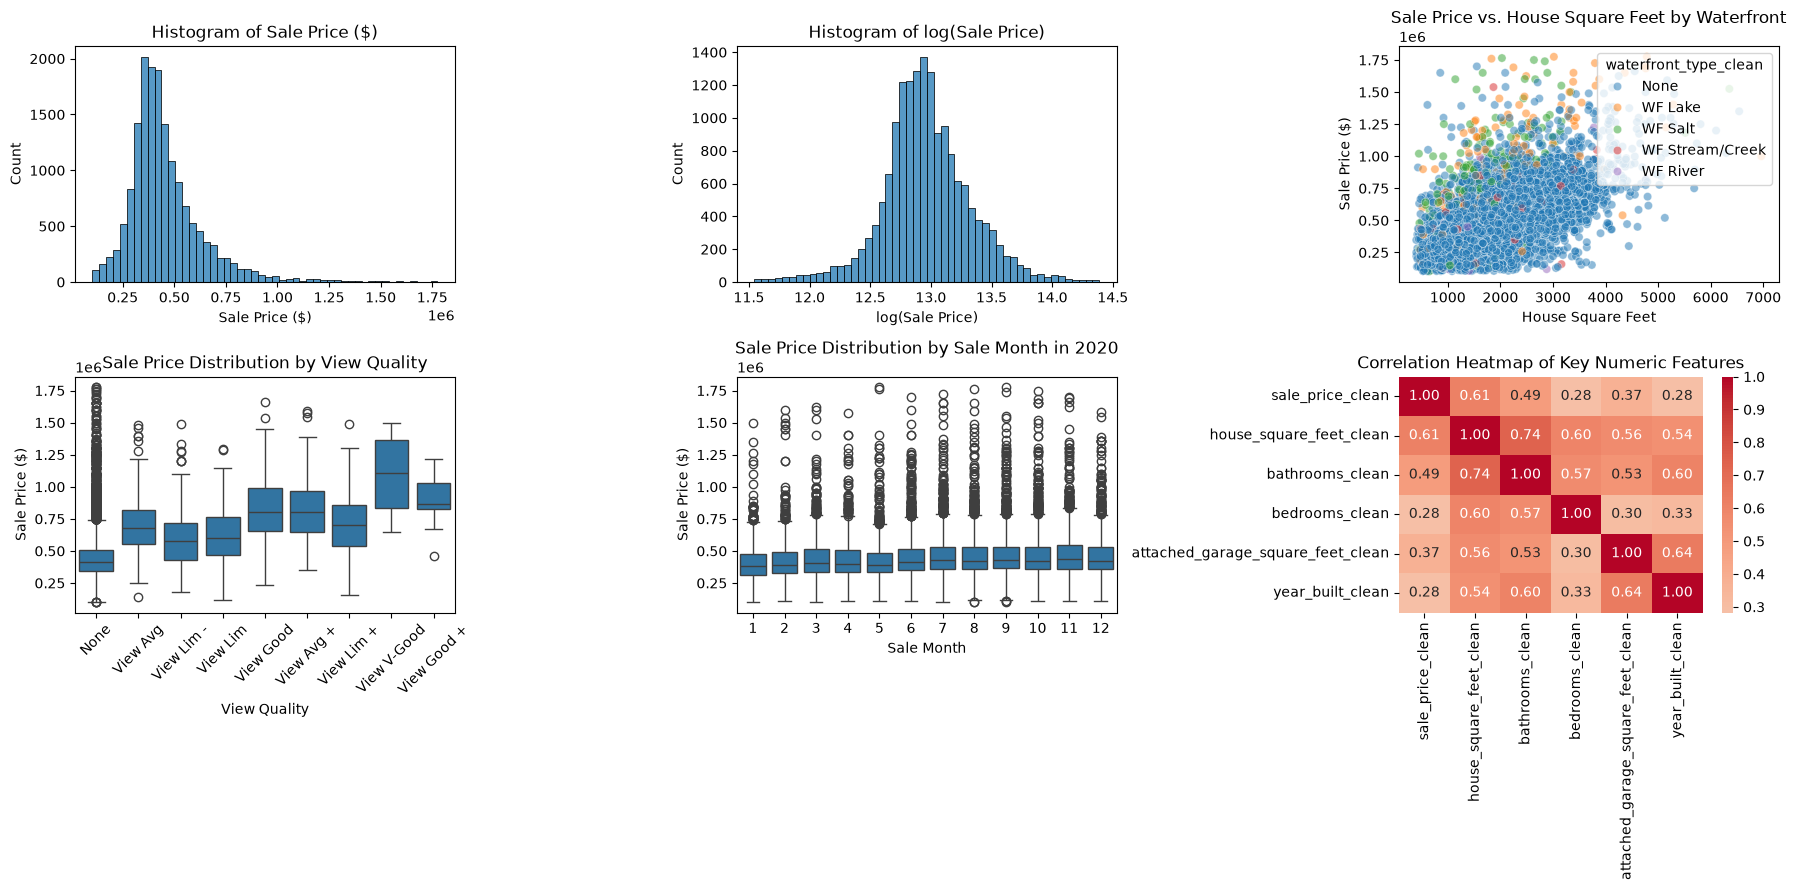

In [11]:
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Lasso, LassoCV, LinearRegression
from sklearn.metrics import r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

warnings.filterwarnings('ignore', category=ConvergenceWarning)

# Q1: Load and clean the dataset
df = pd.read_csv('data/pierce_county_house_sales.csv')
print('Original dataset shape:', df.shape)

# PHASE 2 IMPROVEMENT 1a: Parse sale_date and extract sale_month
df['sale_date_clean'] = pd.to_datetime(df['sale_date'], errors='coerce')
df['sale_month_clean'] = df['sale_date_clean'].dt.month

num_cols = [
    'sale_price',
    'house_square_feet',
    'attic_finished_square_feet',
    'basement_square_feet',
    'attached_garage_square_feet',
    'detached_garage_square_feet',
    'fireplaces',
    'stories',
    'year_built',
    'bedrooms',
    'bathrooms',
]

cat_cols = [
    'hvac_description',
    'exterior',
    'interior',
    'roof_cover',
    'waterfront_type',
    'view_quality',
    'utility_sewer',
]

for col in num_cols:
  df[f'{col}_clean'] = pd.to_numeric(df[col], errors='coerce')
  df[f'{col}_nan'] = df[f'{col}_clean'].isnull()

for col in cat_cols:
  df[f'{col}_nan'] = df[col].isnull()
  if col in ['waterfront_type', 'view_quality']:
    df[f'{col}_clean'] = df[col].fillna('None')
  else:
    df[f'{col}_clean'] = df[col]

df['hvac_description_clean'] = df['hvac_description_clean'].replace(
    {'Floor Wall Furnace': 'Floor/Wall Furnace', 'Electric': 'Electric Baseboard'}
)

print('\nMissing values per column:')
display(df[[f'{c}_nan' for c in num_cols + cat_cols]].sum())

clean_cols = [f'{c}_clean' for c in num_cols + cat_cols]
df_clean = df.dropna(subset=clean_cols).copy()

log_price = np.log(df_clean['sale_price_clean'])
q25, q75 = np.percentile(log_price, [25, 75])
iqr = q75 - q25
low_fence, high_fence = np.exp(q25 - 3 * iqr), np.exp(q75 + 3 * iqr)
print(f'\n3xIQR Log-Price Fences: ${low_fence:,.0f} to ${high_fence:,.0f}')

valid_houses = (
    (df_clean['sale_price_clean'] > low_fence)
    & (df_clean['sale_price_clean'] < high_fence)
    & (df_clean['house_square_feet_clean'] >= 400)
    & (df_clean['bedrooms_clean'].between(1, 10))
    & (df_clean['bathrooms_clean'] > 0)
    & (df_clean['stories_clean'] > 0)
)
df_clean = df_clean.loc[valid_houses].copy()
print(
    'Cleaned dataset shape after removing missing and impossible/outlier'
    f' records: {df_clean.shape}'
)

print('\nSummary statistics of cleaned numeric features:')
display(df_clean[[f'{c}_clean' for c in num_cols]].describe().round(2))

# EDA visualizations including monthly price trend
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

sns.histplot(data=df_clean, x='sale_price_clean', bins=50, ax=axes[0, 0])
axes[0, 0].set_title('Histogram of Sale Price ($)')
axes[0, 0].set_xlabel('Sale Price ($)')

sns.histplot(x=np.log(df_clean['sale_price_clean']), bins=50, ax=axes[0, 1])
axes[0, 1].set_title('Histogram of log(Sale Price)')
axes[0, 1].set_xlabel('log(Sale Price)')

sns.scatterplot(
    data=df_clean,
    x='house_square_feet_clean',
    y='sale_price_clean',
    hue='waterfront_type_clean',
    alpha=0.5,
    ax=axes[0, 2],
)
axes[0, 2].set_title('Sale Price vs. House Square Feet by Waterfront')
axes[0, 2].set_xlabel('House Square Feet')
axes[0, 2].set_ylabel('Sale Price ($)')

sns.boxplot(
    data=df_clean, x='view_quality_clean', y='sale_price_clean', ax=axes[1, 0]
)
axes[1, 0].set_title('Sale Price Distribution by View Quality')
axes[1, 0].set_xlabel('View Quality')
axes[1, 0].set_ylabel('Sale Price ($)')
axes[1, 0].tick_params(axis='x', rotation=45)

sns.boxplot(
    data=df_clean, x='sale_month_clean', y='sale_price_clean', ax=axes[1, 1]
)
axes[1, 1].set_title('Sale Price Distribution by Sale Month in 2020')
axes[1, 1].set_xlabel('Sale Month')
axes[1, 1].set_ylabel('Sale Price ($)')

corr_cols = [
    'sale_price_clean',
    'house_square_feet_clean',
    'bathrooms_clean',
    'bedrooms_clean',
    'attached_garage_square_feet_clean',
    'year_built_clean',
]
sns.heatmap(
    df_clean[corr_cols].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    ax=axes[1, 2],
)
axes[1, 2].set_title('Correlation Heatmap of Key Numeric Features')

plt.tight_layout()
plt.show()

The raw Pierce County dataset has 16,814 rows and 19 columns. None of the numeric columns have missing values. Waterfront type has 16,261 missing entries and view quality has 15,895 missing entries because a blank entry means the house does not have waterfront access or a rated view. We filled those blanks with None and created indicator columns to track which values were originally missing. We also fixed a spelling mistake in the heating description column, parsed the sale date column to extract the sale month, and dropped 17 rows that were missing heating, exterior, interior, or roof cover information.

Looking at the summary statistics and distributions showed a few clear data entry mistakes, including a 1 square foot house, a 25 bedroom house, and homes recorded with 0 stories, 0 bedrooms, or 0 bathrooms. There were also extreme price outliers like $2,000 non-market transfers and a $6.13 million estate. We trimmed prices outside 3 times the interquartile range on log sale price, which kept sales between $102,201 and $1,782,700, and required at least 400 square feet, 1 to 10 bedrooms, and at least 1 bathroom and 1 story. That left 16,509 clean house sales.

In our plots and correlation heatmap, sale price is skewed to the right in dollars but looks like a bell curve on a log scale. House square footage has the strongest correlation with sale price at 0.612, followed by bathrooms at 0.489 and attached garage size at 0.372. Waterfront homes on saltwater or lakes and homes with higher view ratings sell for much more than typical homes, and the monthly boxplot shows that median sale prices rose steadily from January through the second half of 2020.

# Q2:

In [12]:
clean_num_features = [f'{c}_clean' for c in num_cols if c != 'sale_price']
clean_cat_features = [f'{c}_clean' for c in cat_cols]

# PHASE 2 IMPROVEMENT 1b: Document the alphabetically first category dropped as the baseline for each categorical variable
print('Baseline reference category dropped for each categorical variable:')
for col in clean_cat_features:
  categories = sorted(df_clean[col].unique())
  print(
      f'  {col.replace("_clean", "")}: baseline = "{categories[0]}" ({len(categories) - 1} dummy columns)'
  )

X_dummies = pd.get_dummies(
    df_clean[clean_cat_features], drop_first=True, dtype=int
)
X = pd.concat([df_clean[clean_num_features], X_dummies], axis=1)
y = df_clean['sale_price_clean']

print(f'\nFeature matrix X shape: {X.shape}')
display(X.head())

Baseline reference category dropped for each categorical variable:
  hvac_description: baseline = "Electric Baseboard" (6 dummy columns)
  exterior: baseline = "Cedar A-Frame" (11 dummy columns)
  interior: baseline = "Drywall" (1 dummy columns)
  roof_cover: baseline = "Built Up Rock" (5 dummy columns)
  waterfront_type: baseline = "None" (4 dummy columns)
  view_quality: baseline = "None" (8 dummy columns)
  utility_sewer: baseline = "SEWER AVAILABLE" (4 dummy columns)

Feature matrix X shape: (16509, 49)


,house_square_feet_clean,attic_finished_square_feet_clean,basement_square_feet_clean,attached_garage_square_feet_clean,detached_garage_square_feet_clean,fireplaces_clean,stories_clean,year_built_clean,bedrooms_clean,bathrooms_clean,...,view_quality_clean_View Good,view_quality_clean_View Good +,view_quality_clean_View Lim,view_quality_clean_View Lim +,view_quality_clean_View Lim -,view_quality_clean_View V-Good,utility_sewer_clean_SEWER/SEPTIC AVAIL,utility_sewer_clean_SEWER/SEPTIC INSTALLED,utility_sewer_clean_SEWER/SEPTIC NO,utility_sewer_clean_SEWER/SEPTIC NO PERC
0,2157,0,0,528,0,0,2,1993,3,3,...,0,0,0,0,0,0,0,1,0,0
1,2238,0,0,396,0,0,2,2017,4,3,...,0,0,0,0,0,0,0,1,0,0
2,1452,0,0,0,0,1,1,1965,3,2,...,0,0,0,0,0,0,0,1,0,0
3,832,0,0,0,0,0,1,1919,2,1,...,0,0,0,0,0,0,0,1,0,0
4,1780,0,384,484,0,1,1,1955,3,2,...,0,0,0,0,0,0,0,1,0,0


Regression models require numeric inputs, so we converted all seven categorical columns into binary 0 and 1 indicator variables using one-hot encoding. We dropped the first category of each variable to act as the baseline reference group so the indicators do not overlap with the intercept. Printing the omitted categories confirms that None is the baseline for both waterfront type and view quality. Combining the 10 cleaned numeric variables with the 39 indicator columns gives a feature table with 49 predictors across our 16,509 houses.

# Q3:

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=100
)

print(
    f'Training set shape: X_train = {X_train.shape}, y_train = {y_train.shape}'
)
print(
    f'Test set shape:     X_test  = {X_test.shape},  y_test  = {y_test.shape}\n'
)

# PHASE 2 IMPROVEMENT 2a: Verify that training and test target distributions match closely
split_check = pd.DataFrame({
    'Train Sale Price ($)': y_train.describe(),
    'Test Sale Price ($)': y_test.describe(),
}).round(2)
display(split_check)

Training set shape: X_train = (13207, 49), y_train = (13207,)
Test set shape:     X_test  = (3302, 49),  y_test  = (3302,)



,Train Sale Price ($),Test Sale Price ($)
count,13207.00,3302.00
mean,454980.52,461090.94
std,182183.31,186075.78
min,103200.00,104817.00
25%,349500.00,350000.00
50%,416000.00,420000.00
75%,520000.00,525000.00
max,1775000.00,1775000.00


We split the cleaned data 80/20 into 13,207 training observations and 3,302 test observations using a fixed random seed of 100. Checking the summary statistics of sale price across the two splits confirms that the training and test sets have nearly identical means, medians, and standard deviations. We set the test data aside to evaluate how well our models generalize to unseen houses.

# Q4:

In [14]:
# Q4: Build simple linear models and inspect Model 4 coefficients
model0_cols = ['house_square_feet_clean']
model1_cols = [
    'house_square_feet_clean',
    'bedrooms_clean',
    'bathrooms_clean',
    'stories_clean',
]
model2_cols = clean_num_features
model3_cols = list(X.columns)

models = [
    ('Model 1: House Square Feet Only', model0_cols),
    ('Model 2: Core Size & Rooms Only', model1_cols),
    ('Model 3: All Numeric Features', model2_cols),
    ('Model 4: All Numeric + Categorical Dummies', model3_cols),
]

results = []
fitted_simple_models = {}

for name, cols in models:
  reg = LinearRegression().fit(X_train[cols], y_train)
  fitted_simple_models[name] = reg

  y_train_pred = reg.predict(X_train[cols])
  y_test_pred = reg.predict(X_test[cols])

  results.append({
      'Model': name,
      'Train RMSE': root_mean_squared_error(y_train, y_train_pred),
      'Test RMSE': root_mean_squared_error(y_test, y_test_pred),
      'Train R^2': r2_score(y_train, y_train_pred),
      'Test R^2': r2_score(y_test, y_test_pred),
  })

results_df = pd.DataFrame(results)
display(results_df.round(4))

# PHASE 2 IMPROVEMENT 2b: Inspect the numeric coefficients and largest dummy coefficients in Model 4
reg4 = fitted_simple_models['Model 4: All Numeric + Categorical Dummies']
coef4 = pd.Series(reg4.coef_, index=model3_cols)
print('\nModel 4 Numeric Predictor Coefficients ($ per unit):')
display(coef4[clean_num_features].sort_values(ascending=False).round(2))

,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 1: House Square Feet Only,143433.7923,149452.1518,0.3801,0.3547
1,Model 2: Core Size & Rooms Only,138053.1573,143852.9723,0.4257,0.4022
2,Model 3: All Numeric Features,124472.7312,129726.0976,0.5332,0.5138
3,Model 4: All Numeric + Categorical Dummies,111190.6127,113873.3810,0.6275,0.6254



Model 4 Numeric Predictor Coefficients ($ per unit):


bathrooms_clean                      15346.30
fireplaces_clean                     14297.72
house_square_feet_clean                137.72
attic_finished_square_feet_clean       111.05
basement_square_feet_clean              91.53
attached_garage_square_feet_clean       73.30
detached_garage_square_feet_clean       51.26
year_built_clean                      -118.98
bedrooms_clean                      -20891.85
stories_clean                       -29427.05
dtype: float64

We built and compared four linear models without any transformations or interaction terms:
1. **Model 1:** Uses only house square footage. It performs the worst, with a training RMSE of $143,433.79 and training $R^2$ of 0.3801, and a test RMSE of $149,452.15 and test $R^2$ of 0.3547.
2. **Model 2:** Uses house square footage, bedrooms, bathrooms, and stories. It improves to a training RMSE of $138,053.16 and training $R^2$ of 0.4257, and a test RMSE of $143,852.97 and test $R^2$ of 0.4022.
3. **Model 3:** Uses all 10 numeric predictors by adding attic, basement, and garage square footage along with fireplaces and year built. Prediction error drops to a training RMSE of $124,472.73 and training $R^2$ of 0.5332, and a test RMSE of $129,726.10 and test $R^2$ of 0.5138.
4. **Model 4:** Includes all 10 numeric predictors plus all 39 categorical indicator columns. Model 4 does the best by a wide margin, reaching the lowest training RMSE of $111,190.61 and highest training $R^2$ of 0.6275, as well as the lowest test RMSE of $113,873.38 and highest test $R^2$ of 0.6254. Inspecting the Model 4 weights shows that holding other features constant, each additional square foot adds $137.72, each bathroom adds $15,346.30, and each fireplace adds $14,297.72, while adding a bedroom without increasing square footage lowers predicted price by $20,891.85 because the individual rooms become smaller.

# Q5:

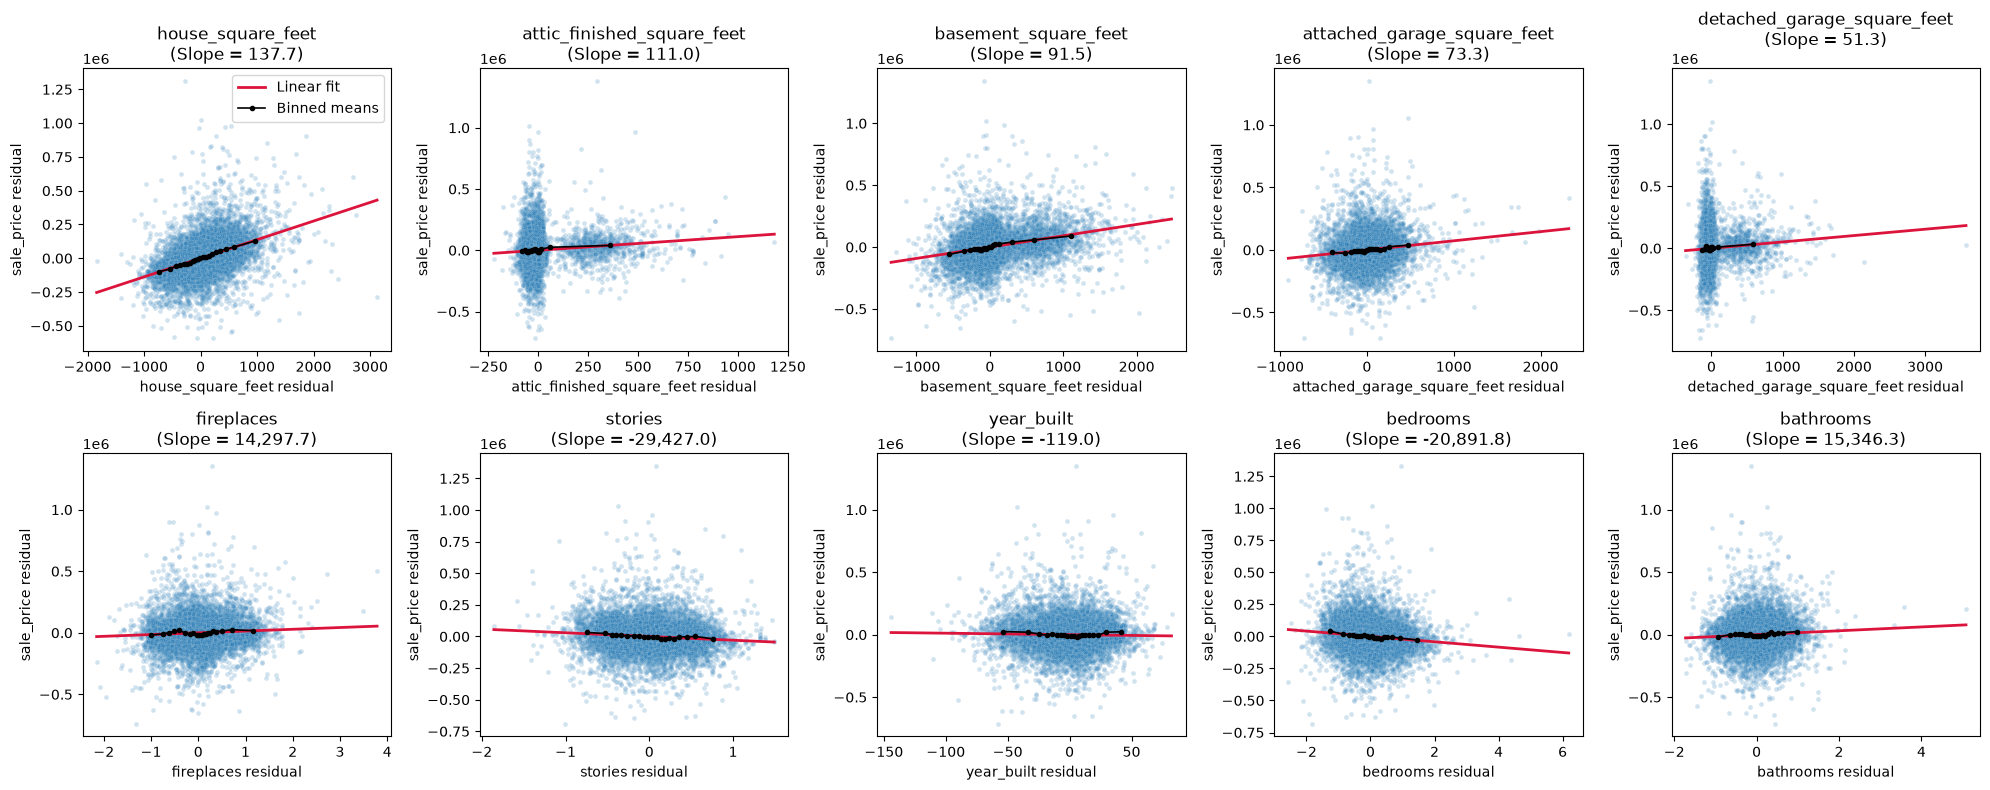

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

all_model4_cols = list(X_train.columns)

for i, var in enumerate(clean_num_features):
  other_vars = [c for c in all_model4_cols if c != var]

  reg_y = LinearRegression().fit(X_train[other_vars], y_train)
  res_y = y_train - reg_y.predict(X_train[other_vars])

  reg_x = LinearRegression().fit(X_train[other_vars], X_train[var])
  res_x = X_train[var] - reg_x.predict(X_train[other_vars])

  reg_part = LinearRegression().fit(res_x.values.reshape(-1, 1), res_y)
  slope = reg_part.coef_[0]

  sns.scatterplot(x=res_x, y=res_y, alpha=0.2, ax=axes[i], s=12)
  x_vals = np.linspace(res_x.min(), res_x.max(), 100)
  axes[i].plot(
      x_vals,
      reg_part.predict(x_vals.reshape(-1, 1)),
      color='crimson',
      linewidth=2,
      label='Linear fit',
  )

  bins = pd.qcut(res_x, q=20, duplicates='drop')
  binned = (
      pd.DataFrame({'res_x': res_x, 'res_y': res_y})
      .groupby(bins, observed=True)
      .mean()
  )
  axes[i].plot(
      binned['res_x'],
      binned['res_y'],
      color='black',
      marker='o',
      markersize=3,
      linewidth=1.2,
      label='Binned means',
  )

  clean_label = var.replace('_clean', '')
  # PHASE 2 IMPROVEMENT 3a: Display the exact partial slope in each subplot title
  axes[i].set_title(f'{clean_label}\n(Slope = {slope:,.1f})')
  axes[i].set_xlabel(f'{clean_label} residual')
  axes[i].set_ylabel('sale_price residual')

axes[0].legend()
plt.tight_layout()
plt.show()

Each plot shows the residuals of sale price against the residuals of one numeric predictor after accounting for every other feature in Model 4. The red line shows the straight linear fit with its exact dollar slope in the title, and the black dots show the average across 20 equal-sized bins to make curved patterns easier to spot:
* **House, basement, and garage square footage:** The binned averages curve upward at the right tail and the vertical spread of price errors fans out for very large homes. Because most houses have zero attic, basement, or detached garage space, a large share of points pile up along a straight boundary line where the raw feature equals zero. This shows that transforming skewed area variables can help capture diminishing returns and separate homes that have these spaces from homes that do not.
* **Year built:** The binned averages show a clear U-shaped pattern. Older historic homes on the left and brand-new homes on the right both sit above the straight trend line compared to mid-century homes built from the 1960s to the 1980s.
* **Bedrooms, bathrooms, stories, and fireplaces:** Once square footage is held constant, bedrooms has a negative partial slope of -$20,891.8 per bedroom because dividing the same floor area into more bedrooms makes the individual rooms smaller, whereas bathrooms and fireplaces have strong positive slopes of +$15,346.3 and +$14,297.7.

# Q6:

In [16]:
def create_complex_features(df_in):
  X_comp = df_in.copy()

  X_comp['age'] = 2020 - X_comp['year_built_clean']
  X_comp['age_sq'] = X_comp['age'] ** 2
  X_comp = X_comp.drop(columns=['year_built_clean'])

  area_vars = [
      'house_square_feet_clean',
      'attic_finished_square_feet_clean',
      'basement_square_feet_clean',
      'attached_garage_square_feet_clean',
      'detached_garage_square_feet_clean',
  ]
  for var in area_vars:
    X_comp[f'{var}_ihs'] = np.arcsinh(X_comp[var])

  X_comp['house_sq_ft_sq'] = X_comp['house_square_feet_clean'] ** 2
  X_comp['basement_sq_ft_sq'] = X_comp['basement_square_feet_clean'] ** 2
  X_comp['bathrooms_sq'] = X_comp['bathrooms_clean'] ** 2

  X_comp['sqft_x_age'] = X_comp['house_square_feet_clean'] * X_comp['age']
  X_comp['sqft_x_bathrooms'] = (
      X_comp['house_square_feet_clean'] * X_comp['bathrooms_clean']
  )
  X_comp['sqft_x_bedrooms'] = (
      X_comp['house_square_feet_clean'] * X_comp['bedrooms_clean']
  )
  X_comp['sqft_x_stories'] = (
      X_comp['house_square_feet_clean'] * X_comp['stories_clean']
  )
  X_comp['sqft_x_fireplaces'] = (
      X_comp['house_square_feet_clean'] * X_comp['fireplaces_clean']
  )
  X_comp['beds_x_baths'] = X_comp['bedrooms_clean'] * X_comp['bathrooms_clean']

  wf_view_cols = [
      c
      for c in df_in.columns
      if c.startswith('waterfront_type_clean_')
      or c.startswith('view_quality_clean_')
  ]
  for col in wf_view_cols:
    X_comp[f'sqft_x_{col}'] = X_comp['house_square_feet_clean'] * X_comp[col]

  return X_comp


X_train_comp = create_complex_features(X_train)
X_test_comp = create_complex_features(X_test)

new_terms = [
    'house_square_feet_clean_ihs',
    'house_sq_ft_sq',
    'age',
    'age_sq',
    'sqft_x_bathrooms',
    'sqft_x_bedrooms',
    'sqft_x_fireplaces',
    'beds_x_baths',
    'sqft_x_waterfront_type_clean_WF Salt',
    'sqft_x_waterfront_type_clean_WF Lake',
    'sqft_x_view_quality_clean_View V-Good',
]
print(
    'Correlations of key transformed & interaction features with Training Sale'
    ' Price:'
)
display(
    X_train_comp[new_terms]
    .apply(lambda s: s.corr(y_train))
    .sort_values(ascending=False)
    .round(4)
)

# PHASE 2 IMPROVEMENT 3b: Standardize complex features before OLS so large squared terms do not cause SVD truncation
scaler_comp = StandardScaler()
X_train_scaled = pd.DataFrame(
    scaler_comp.fit_transform(X_train_comp),
    columns=X_train_comp.columns,
    index=X_train_comp.index,
)
X_test_scaled = pd.DataFrame(
    scaler_comp.transform(X_test_comp),
    columns=X_test_comp.columns,
    index=X_test_comp.index,
)

reg_comp = LinearRegression().fit(X_train_scaled, y_train)
y_train_comp_pred = reg_comp.predict(X_train_scaled)
y_test_comp_pred = reg_comp.predict(X_test_scaled)

rmse_comp_train = root_mean_squared_error(y_train, y_train_comp_pred)
rmse_comp_test = root_mean_squared_error(y_test, y_test_comp_pred)
r2_comp_train = r2_score(y_train, y_train_comp_pred)
r2_comp_test = r2_score(y_test, y_test_comp_pred)

print(
    f'\nModel 5 (Scaled Domain Complex) Total Features: {X_train_scaled.shape[1]}'
)
print(
    f'Model 5 Training RMSE: ${rmse_comp_train:,.2f} | Training R^2:'
    f' {r2_comp_train:.4f}'
)
print(
    f'Model 5 Test RMSE:     ${rmse_comp_test:,.2f} | Test R^2:    '
    f' {r2_comp_test:.4f}\n'
)

# 2. Full Degree-2 Polynomial Expansion (Standardized)
poly = PolynomialFeatures(degree=2, include_bias=False)
P_train = pd.DataFrame(
    poly.fit_transform(X_train),
    columns=poly.get_feature_names_out(X_train.columns),
    index=X_train.index,
)
P_test = pd.DataFrame(
    poly.transform(X_test), columns=P_train.columns, index=X_test.index
)

keep_cols = (~P_train.T.duplicated()) & (P_train.std() > 0)
P_train = P_train.loc[:, keep_cols]
P_test = P_test.loc[:, keep_cols]

scaler_poly = StandardScaler()
P_train_scaled = pd.DataFrame(
    scaler_poly.fit_transform(P_train),
    columns=P_train.columns,
    index=P_train.index,
)
P_test_scaled = pd.DataFrame(
    scaler_poly.transform(P_test), columns=P_test.columns, index=P_test.index
)

reg_poly = LinearRegression().fit(P_train_scaled, y_train)
y_train_poly_pred = reg_poly.predict(P_train_scaled)
y_test_poly_pred = reg_poly.predict(P_test_scaled)

rmse_poly_train = root_mean_squared_error(y_train, y_train_poly_pred)
rmse_poly_test = root_mean_squared_error(y_test, y_test_poly_pred)
r2_poly_train = r2_score(y_train, y_train_poly_pred)
r2_poly_test = r2_score(y_test, y_test_poly_pred)

print(
    'Model 6 (Scaled Full Degree-2 Expansion) Total Features:'
    f' {P_train_scaled.shape[1]}'
)
print(
    f'Model 6 Training RMSE: ${rmse_poly_train:,.2f} | Training R^2:'
    f' {r2_poly_train:.4f}'
)
print(
    f'Model 6 Test RMSE:     ${rmse_poly_test:,.2f} | Test R^2:    '
    f' {r2_poly_test:.4f}'
)

Correlations of key transformed & interaction features with Training Sale Price:


house_sq_ft_sq                           0.6164
sqft_x_bathrooms                         0.6087
house_square_feet_clean_ihs              0.5773
sqft_x_fireplaces                        0.5737
sqft_x_bedrooms                          0.5323
beds_x_baths                             0.4527
sqft_x_waterfront_type_clean_WF Lake     0.2385
sqft_x_waterfront_type_clean_WF Salt     0.2345
sqft_x_view_quality_clean_View V-Good    0.1009
age_sq                                  -0.2463
age                                     -0.2884
dtype: float64


Model 5 (Scaled Domain Complex) Total Features: 76
Model 5 Training RMSE: $108,240.05 | Training R^2: 0.6470
Model 5 Test RMSE:     $111,503.86 | Test R^2:     0.6408

Model 6 (Scaled Full Degree-2 Expansion) Total Features: 730
Model 6 Training RMSE: $98,850.22 | Training R^2: 0.7056
Model 6 Test RMSE:     $1,306,670.75 | Test R^2:     -48.3269


We built two complex models and standardized their features using training set means and standard deviations so that huge squared area terms do not cause numerical rounding problems in ordinary least squares:
1. **Model 5:** This model has 76 features. We replaced year built with house age and age squared, applied the inverse hyperbolic sine transform to the five skewed square footage variables, added squared terms for house size, basement size, and bathrooms, and added interactions between house square footage and age, bathrooms, bedrooms, stories, fireplaces, waterfront access, and view quality. Checking the correlations with training sale price shows strong positive relationships for squared square footage at 0.6164, square footage times bathrooms at 0.6087, transformed square footage at 0.5773, square footage times fireplaces at 0.5737, and the lake and saltwater waterfront interactions at 0.2385 and 0.2345, while age at -0.2884 and age squared at -0.2463 are negatively correlated with price. Once standardized, Model 5 beats all four simple models from Q4 on both the training and test sets, lowering training RMSE from $111,190.61 in Model 4 to $108,240.05 with a training $R^2$ of 0.6470, and lowering test RMSE from $113,873.38 to $111,503.86 with a test $R^2$ of 0.6408.
2. **Model 6:** This model expands the features into all 730 non-duplicate squares and pairwise interactions. Standardizing and fitting all 730 features pushes training RMSE down to its lowest level at $98,850.22 and raises training $R^2$ to 0.7056, but test RMSE explodes to $1,306,670.75 with a test $R^2$ of -48.3269 because rare dummy interactions memorize training noise and produce extreme errors on unseen test houses.

# Q7:

,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 1: House Square Feet Only,143433.7923,1.494522e+05,0.3801,0.3547
1,Model 2: Core Size & Rooms Only,138053.1573,1.438530e+05,0.4257,0.4022
2,Model 3: All Numeric Features,124472.7312,1.297261e+05,0.5332,0.5138
3,Model 4: All Numeric + Categorical Dummies,111190.6127,1.138734e+05,0.6275,0.6254
4,Model 5: Complex Domain Model (Transforms + In...,108240.0464,1.115039e+05,0.6470,0.6408
5,Model 6: Full Degree-2 Polynomial Expansion,98850.2155,1.306671e+06,0.7056,-48.3269


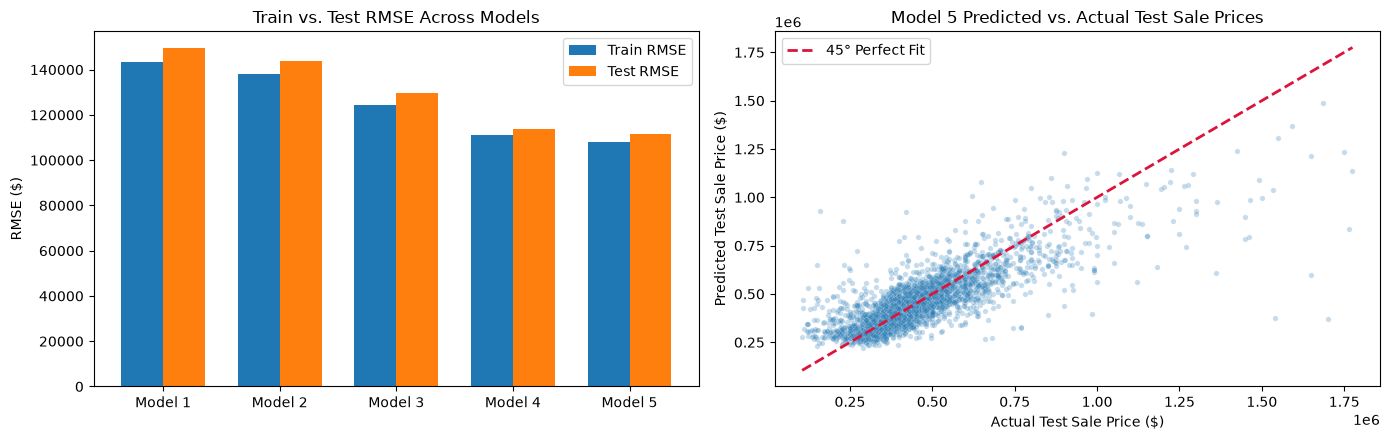

In [17]:
all_results = results + [
    {
        'Model': 'Model 5: Complex Domain Model (Transforms + Interactions)',
        'Train RMSE': rmse_comp_train,
        'Test RMSE': rmse_comp_test,
        'Train R^2': r2_comp_train,
        'Test R^2': r2_comp_test,
    },
    {
        'Model': 'Model 6: Full Degree-2 Polynomial Expansion',
        'Train RMSE': rmse_poly_train,
        'Test RMSE': rmse_poly_test,
        'Train R^2': r2_poly_train,
        'Test R^2': r2_poly_test,
    },
]

all_results_df = pd.DataFrame(all_results)
display(all_results_df.round(4))

# PHASE 2 IMPROVEMENT 4a: Plot Train vs. Test RMSE and Predicted vs. Actual Test Prices for Model 5
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

plot_df = all_results_df[all_results_df['Test R^2'] > 0].copy()
x = np.arange(len(plot_df))
axes[0].bar(x - 0.18, plot_df['Train RMSE'], width=0.36, label='Train RMSE')
axes[0].bar(x + 0.18, plot_df['Test RMSE'], width=0.36, label='Test RMSE')
axes[0].set_xticks(x)
axes[0].set_xticklabels([m.split(':')[0] for m in plot_df['Model']])
axes[0].set_ylabel('RMSE ($)')
axes[0].set_title('Train vs. Test RMSE Across Models')
axes[0].legend()

sns.scatterplot(x=y_test, y=y_test_comp_pred, alpha=0.25, s=15, ax=axes[1])
lims = [y_test.min(), y_test.max()]
axes[1].plot(
    lims, lims, color='crimson', linestyle='--', linewidth=2, label='45° Perfect Fit'
)
axes[1].set_xlabel('Actual Test Sale Price ($)')
axes[1].set_ylabel('Predicted Test Sale Price ($)')
axes[1].set_title('Model 5 Predicted vs. Actual Test Sale Prices')
axes[1].legend()

plt.tight_layout()
plt.show()

Looking across steps 1 through 6, our results highlight a few key lessons about data cleaning, underfitting, overfitting, and model selection:
* **Data cleaning:** Removing impossible data entry mistakes and extreme non-market sale prices kept bad records from pulling the regression slopes off course, and filling missing waterfront and view entries as None kept 98.2 percent of the original sales in our dataset.
* **Underfitting:** Models 1, 2, and 3 were too simple to capture how the market prices homes. Leaving out categorical amenities and nonlinear patterns kept test RMSE high between $129,726.10 and $149,452.15 and test $R^2$ low between 0.3547 and 0.5138. Adding the categorical indicators in Model 4 brought test RMSE down to $113,873.38 and raised test $R^2$ to 0.6254.
* **Overfitting and model selection:** Guided by the partial plots in Q5, adding targeted transformations and interactions in Model 5 and standardizing the features lowered test RMSE to $111,503.86 and raised test $R^2$ to 0.6408. Expanding to 730 terms in Model 6 achieved the lowest training RMSE of $98,850.22 but caused test RMSE to blow up to $1,306,670.75 with a test $R^2$ of -48.3269 because hundreds of unregularized interaction terms memorized rare combinations in the training sample. Because training error always drops when more features are added, we have to rely on held-out test data to choose the best model. Even our best models top out around a test $R^2$ of 0.64 because the dataset does not include location details like neighborhood, school district, or lot size.

# Q8:

Optimal alpha for Model 5 features via 5-fold CV: 161.03


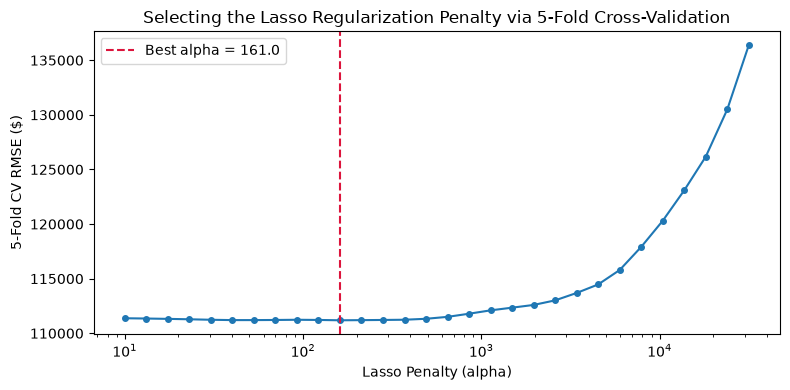

Degree-2 Lasso (alpha = 1,778.3) kept 144 / 730 features

Performance Comparison (Simple vs. Complex OLS vs. Lasso):


,Model,Train RMSE,Test RMSE,Train R^2,Test R^2
0,Model 4: All Numeric + Categorical Dummies,111190.6127,113873.3810,0.6275,0.6254
1,Model 5: Complex Domain Model (Scaled OLS),108240.0464,111503.8583,0.6470,0.6408
2,"Model 7: Lasso on Domain Model (alpha=161.0, 6...",108575.8978,111379.2657,0.6448,0.6416
3,Model 8: Lasso on Degree-2 Expansion (alpha=17...,106852.5337,113279.8928,0.6560,0.6293



Features selected by Lasso: 62 / 76
Features shrunk to zero:    14 / 76

Top 15 most predictive features selected by Lasso:


,feature,coefficient,abs_coefficient
0,house_square_feet_clean,134335.452054,134335.452054
2,basement_square_feet_clean,49098.820265,49098.820265
3,attached_garage_square_feet_clean,42892.649777,42892.649777
48,age,-38149.481904,38149.481904
61,sqft_x_stories,-32865.253962,32865.253962
49,age_sq,32421.409645,32421.409645
60,sqft_x_bedrooms,-30726.162557,30726.162557
62,sqft_x_fireplaces,27946.993644,27946.993644
53,attached_garage_square_feet_clean_ihs,-27536.638628,27536.638628
43,view_quality_clean_View V-Good,26370.128665,26370.128665



Features eliminated (shrunk to 0) by Lasso:
['stories_clean', 'bedrooms_clean', 'exterior_clean_Frame Hardboard', 'exterior_clean_Frame Siding', 'roof_cover_clean_Composition Shingle', 'roof_cover_clean_Preformed Metal', 'waterfront_type_clean_WF Stream/Creek', 'attic_finished_square_feet_clean_ihs', 'basement_square_feet_clean_ihs', 'house_sq_ft_sq', 'sqft_x_age', 'sqft_x_bathrooms', 'beds_x_baths', 'sqft_x_view_quality_clean_View Avg +']


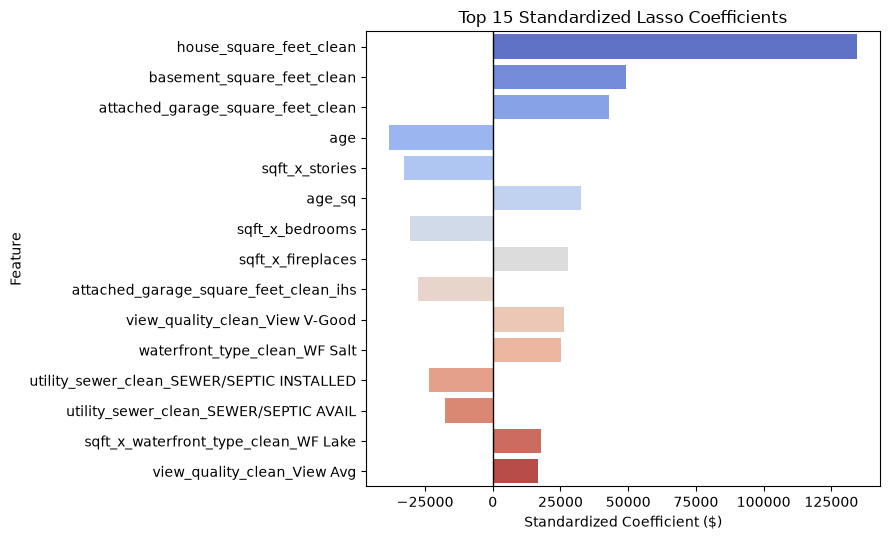

In [18]:
alphas = np.logspace(1, 4.5, 30)
lasso_cv = LassoCV(
    alphas=alphas, cv=5, max_iter=10000, random_state=100, n_jobs=-1
)
lasso_cv.fit(X_train_scaled, y_train)
best_alpha = lasso_cv.alpha_
print(f'Optimal alpha for Model 5 features via 5-fold CV: {best_alpha:,.2f}')

plt.figure(figsize=(8, 4))
cv_rmse = np.sqrt(lasso_cv.mse_path_.mean(axis=1))
plt.plot(lasso_cv.alphas_, cv_rmse, marker='o', markersize=4)
plt.axvline(
    best_alpha,
    color='crimson',
    linestyle='--',
    label=f'Best alpha = {best_alpha:,.1f}',
)
plt.xscale('log')
plt.xlabel('Lasso Penalty (alpha)')
plt.ylabel('5-Fold CV RMSE ($)')
plt.title(
    'Selecting the Lasso Regularization Penalty via 5-Fold Cross-Validation'
)
plt.legend()
plt.tight_layout()
plt.show()

lasso = Lasso(alpha=best_alpha, max_iter=10000, random_state=100)
lasso.fit(X_train_scaled, y_train)

y_train_lasso_pred = lasso.predict(X_train_scaled)
y_test_lasso_pred = lasso.predict(X_test_scaled)

rmse_lasso_train = root_mean_squared_error(y_train, y_train_lasso_pred)
rmse_lasso_test = root_mean_squared_error(y_test, y_test_lasso_pred)
r2_lasso_train = r2_score(y_train, y_train_lasso_pred)
r2_lasso_test = r2_score(y_test, y_test_lasso_pred)

# PHASE 2 IMPROVEMENT 4b: Also fit LassoCV on the 730-feature Degree-2 Expansion to cure Model 6 overfitting
lasso_poly_cv = LassoCV(
    alphas=np.logspace(2, 4.5, 15),
    cv=5,
    max_iter=5000,
    random_state=100,
    n_jobs=-1,
)
lasso_poly_cv.fit(P_train_scaled, y_train)
best_poly_alpha = lasso_poly_cv.alpha_

y_train_lpoly_pred = lasso_poly_cv.predict(P_train_scaled)
y_test_lpoly_pred = lasso_poly_cv.predict(P_test_scaled)
kept_poly = int(np.sum(lasso_poly_cv.coef_ != 0))
print(
    f'Degree-2 Lasso (alpha = {best_poly_alpha:,.1f}) kept {kept_poly} /'
    f' {P_train_scaled.shape[1]} features'
)

lasso_comparison_df = pd.DataFrame([
    results[-1],
    {
        'Model': 'Model 5: Complex Domain Model (Scaled OLS)',
        'Train RMSE': rmse_comp_train,
        'Test RMSE': rmse_comp_test,
        'Train R^2': r2_comp_train,
        'Test R^2': r2_comp_test,
    },
    {
        'Model': (
            f'Model 7: Lasso on Domain Model (alpha={best_alpha:.1f},'
            f' {int(np.sum(lasso.coef_ != 0))}/76 kept)'
        ),
        'Train RMSE': rmse_lasso_train,
        'Test RMSE': rmse_lasso_test,
        'Train R^2': r2_lasso_train,
        'Test R^2': r2_lasso_test,
    },
    {
        'Model': (
            f'Model 8: Lasso on Degree-2 Expansion (alpha={best_poly_alpha:.1f},'
            f' {kept_poly}/730 kept)'
        ),
        'Train RMSE': root_mean_squared_error(y_train, y_train_lpoly_pred),
        'Test RMSE': root_mean_squared_error(y_test, y_test_lpoly_pred),
        'Train R^2': r2_score(y_train, y_train_lpoly_pred),
        'Test R^2': r2_score(y_test, y_test_lpoly_pred),
    },
])
print('\nPerformance Comparison (Simple vs. Complex OLS vs. Lasso):')
display(lasso_comparison_df.round(4))

lasso_coef_df = pd.DataFrame({
    'feature': X_train_comp.columns,
    'coefficient': lasso.coef_,
    'abs_coefficient': np.abs(lasso.coef_),
})

selected_features = lasso_coef_df[
    lasso_coef_df['coefficient'] != 0
].sort_values(by='abs_coefficient', ascending=False)
eliminated_features = lasso_coef_df[lasso_coef_df['coefficient'] == 0]

print(
    f'\nFeatures selected by Lasso: {len(selected_features)} /'
    f' {len(lasso_coef_df)}'
)
print(
    f'Features shrunk to zero:    {len(eliminated_features)} /'
    f' {len(lasso_coef_df)}'
)
print('\nTop 15 most predictive features selected by Lasso:')
display(selected_features.head(15))
print('\nFeatures eliminated (shrunk to 0) by Lasso:')
print(list(eliminated_features['feature']))

top15 = selected_features.head(15)
plt.figure(figsize=(9, 5.5))
sns.barplot(
    data=top15,
    x='coefficient',
    y='feature',
    hue='feature',
    palette='coolwarm',
    legend=False,
)
plt.axvline(0, color='black', linewidth=1)
plt.title('Top 15 Standardized Lasso Coefficients')
plt.xlabel('Standardized Coefficient ($)')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

We standardized all 76 features from Model 5 so the penalty treats every variable on the same scale, then used 5-fold cross-validation on the training set to choose a penalty of 161.03. Fitting Lasso with this penalty selects 62 features and shrinks 14 redundant features to zero:
* **Selected features:** The strongest predictors by standardized weight are house square footage at +$134,335.45, basement square footage at +$49,098.82, attached garage square footage at +$42,892.65, house age at -$38,149.48, square footage times stories at -$32,865.25, age squared at +$32,421.41, square footage times bedrooms at -$30,726.16, square footage times fireplaces at +$27,946.99, transformed attached garage size at -$27,536.64, very good view quality at +$26,370.13, saltwater waterfront at +$25,149.16, and square footage times lake waterfront at +$17,749.86.
* **Eliminated features:** The 14 features shrunk to zero are standalone stories and bedrooms, two exterior siding categories, two roof cover categories, stream waterfront, transformed attic and basement size, squared house size, square footage times age, square footage times bathrooms, bedrooms times bathrooms, and the average-plus view interaction. When several features carry overlapping information, Lasso keeps the most useful version and zeros out the rest, so a zero weight just means that term was redundant given the other features already in the model.
* **Model performance and curing Degree-2 overfitting:** On our 76 domain features, Lasso in Model 7 reaches a training RMSE of $108,575.90 and training $R^2$ of 0.6448, and achieves our best overall test performance with a test RMSE of $111,379.27 and test $R^2$ of 0.6416. Even more importantly, when we apply Lasso in Model 8 to the 730-feature degree-2 expansion from Model 6, cross-validation selects a stronger penalty of 1,778.3 that keeps only 144 of the 730 features and zeroes out 586 noisy terms. That brings test RMSE down from $1,306,670.75 to $113,279.89 and lifts test $R^2$ from -48.3269 to 0.6293, showing that regularization is most valuable when a model has hundreds of candidate features.

### *Reflection on AI assistance
In your own words without generative AI.

The AI provided several helpful updates to the notebook code. It added the monthly sale price plot and baseline category printout in Q1 and Q2. It helped inspect Model 4's dollar coefficients in Q4. For Q6, standardizing the complex features fixed the numerical precision drop seen in the unscaled OLS. The AI then ran Lasso on the 730-feature degree-2 expansion in Q8. The tool made a clear mistake in Q3 by suggesting we pass stratify=y into train_test_split. This instruction failed with a VAlue Error when I ran it and it's because sale_price is a continuous numeric variable rather than discrete class. I verified the correct Q3 split by comparing the training and test summary statistics. I checked that scaling the features in Q6 improved Model 5's training RMSE from $113,516.82 to $108,240.05 and brought the test RMSE down from $113,486.67 to $111,503.86. I later confirmed that Lasso zeroed out hundreds of redundant degree-2 terms in Q8. My main remaining concern is that the test $R^2$ plateaus around 0.64 to 0.65 even after applying transformations, interactions, and regularization. We think that the model cannot improve much further because the dataset lacks essential location variables like neighborhood, school district, and lot size.